# Results overview

## Comparison of the 4 ABCInML baselines — Logistic Regression (monthly)

Analysis based on the aggregated results in `src/results/all/assessment_all_baselines.csv`.

- **Filter:** `model_name == 'logistic_regression'` and `batch_type == 'monthly'`
- **Aggregation:** the metrics are aggregated by the **mean per batch** within each baseline (collapsing the different runs: alphas, forecasting techniques and windows)
- **Chart:** follows the same logic as `metrics_utils._generate_comparative_chart` (moving averages per baseline, one subplot per metric, with the epidemiological periods in the background)

In [1]:
import sys
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt

# The notebook lives in src/notebooks/ -> repo root is two levels up
ROOT = Path.cwd().resolve()
while not (ROOT / 'src' / 'utils' / 'metrics_utils.py').exists():
    ROOT = ROOT.parent
sys.path.append(str(ROOT / 'src' / 'utils'))

import metrics_utils
from metrics_utils import _SNAPSHOT_METRICS

In [2]:
# Load the aggregated results of all runs
assessment_df = pd.read_csv(ROOT / 'src' / 'results' / 'all' / 'assessment_all_baselines.csv')

# Keep only Kamiran & Calders (fairness_correction == 'kamiran_rw'): the aggregated
# file now also contains APR runs ('adaptative_rw'), which reweigh
# static/dynamic/abcinml differently and only partially cover the grid
# (not every alpha × technique × window combination was run) — mixing them here
# would bias the means. The comparison with APR is left for a separate analysis.
assessment_df = assessment_df[assessment_df['fairness_correction'] == 'kamiran_rw'].copy()

# Fix the forecasting technique to 'sma' in the main figures (ema/oracle are left
# for separate analyses). The non-abc baselines are all 'sma', so the filter
# only removes the ema/oracle rows of abcinml.
assessment_df = assessment_df[assessment_df['forecasting_technique'] == 'sma'].copy()

# Filter: logistic regression only, split by batch type
lr_df = assessment_df[assessment_df['model_name'] == 'logistic_regression']
lr_monthly_df = lr_df[lr_df['batch_type'] == 'monthly'].copy()
lr_weekly_df = lr_df[lr_df['batch_type'] == 'weekly'].copy()

print(f'Total rows (all runs): {len(assessment_df)}')
print(f'LR monthly: {len(lr_monthly_df)} rows | LR weekly: {len(lr_weekly_df)} rows')
lr_monthly_df.groupby('baseline').size()

Total rows (all runs): 219487
LR monthly: 12000 rows | LR weekly: 52950 rows


baseline
abcinml    10560
dynamic      960
static       240
vanilla      240
dtype: int64

### Aggregation: mean of the metrics per batch

The `vanilla`, `static` and `dynamic` baselines have one run per batch; `abcinml` has several (11 alphas × forecasting techniques × windows). The mean per `(baseline, batch)` collapses this variation — the same aggregation done internally by `_generate_comparative_chart`.

In [3]:
metric_cols = [col for col, _ in _SNAPSHOT_METRICS]

mean_per_batch = (
    lr_monthly_df
    .groupby(['baseline', 'batch'], as_index=False)[metric_cols]
    .mean()
)

print(f'{len(mean_per_batch)} rows (baseline x batch)')
mean_per_batch.head(10)

332 rows (baseline x batch)


,baseline,batch,acc,auc,dp,tpr_diff,fpr_diff,eq_odds_diff
0,abcinml,2019-04,0.906934,0.841955,0.047591,0.049865,0.014445,0.049865
1,abcinml,2019-05,0.895545,0.842751,0.014115,0.133431,0.002738,0.133431
2,abcinml,2019-06,0.882527,0.817052,0.004016,0.181879,0.007912,0.181879
3,abcinml,2019-07,0.857049,0.817750,0.004605,0.186457,0.000881,0.186457
4,abcinml,2019-08,0.872320,0.817609,0.015596,0.130305,0.004732,0.130305
5,abcinml,2019-09,0.892639,0.825869,0.015843,0.148080,0.012299,0.148080
6,abcinml,2019-10,0.883790,0.841549,0.025766,0.120213,0.009474,0.120213
7,abcinml,2019-11,0.898038,0.851947,0.030847,0.183859,0.018776,0.183859
8,abcinml,2019-12,0.875483,0.804220,0.007549,0.133851,0.007341,0.133851
9,abcinml,2020-01,0.848389,0.799836,0.009873,0.047909,0.014269,0.047916


In [4]:
# Overall summary: mean of each metric per baseline (over the batches)
(
    mean_per_batch
    .groupby('baseline')[metric_cols]
    .mean()
    .reindex(['vanilla', 'static', 'dynamic', 'abcinml'])
    .round(4)
)

,acc,auc,dp,tpr_diff,fpr_diff,eq_odds_diff
baseline,,,,,,
vanilla,0.8612,0.8283,0.1877,0.2059,0.1182,0.2136
static,0.8590,0.7813,0.0457,0.0872,0.0181,0.0890
dynamic,0.8696,0.8080,0.0369,0.1401,0.0068,0.1401
abcinml,0.8692,0.8049,0.0346,0.1485,0.0064,0.1485


### Comparative chart of the 4 baselines — monthly and weekly

Two rows of subplots (one per `batch_type`), each following the same logic as `metrics_utils._generate_comparative_chart`:
1. aggregates the metrics by the mean per `(baseline, batch)`;
2. applies a moving average (5 batches for monthly, 20 for weekly — the pipeline defaults);
3. restricts to the batch range common to all baselines;
4. draws one subplot per metric (Accuracy, AUC-ROC, DP, TPR diff, FPR diff) with the epidemiological periods in the background.

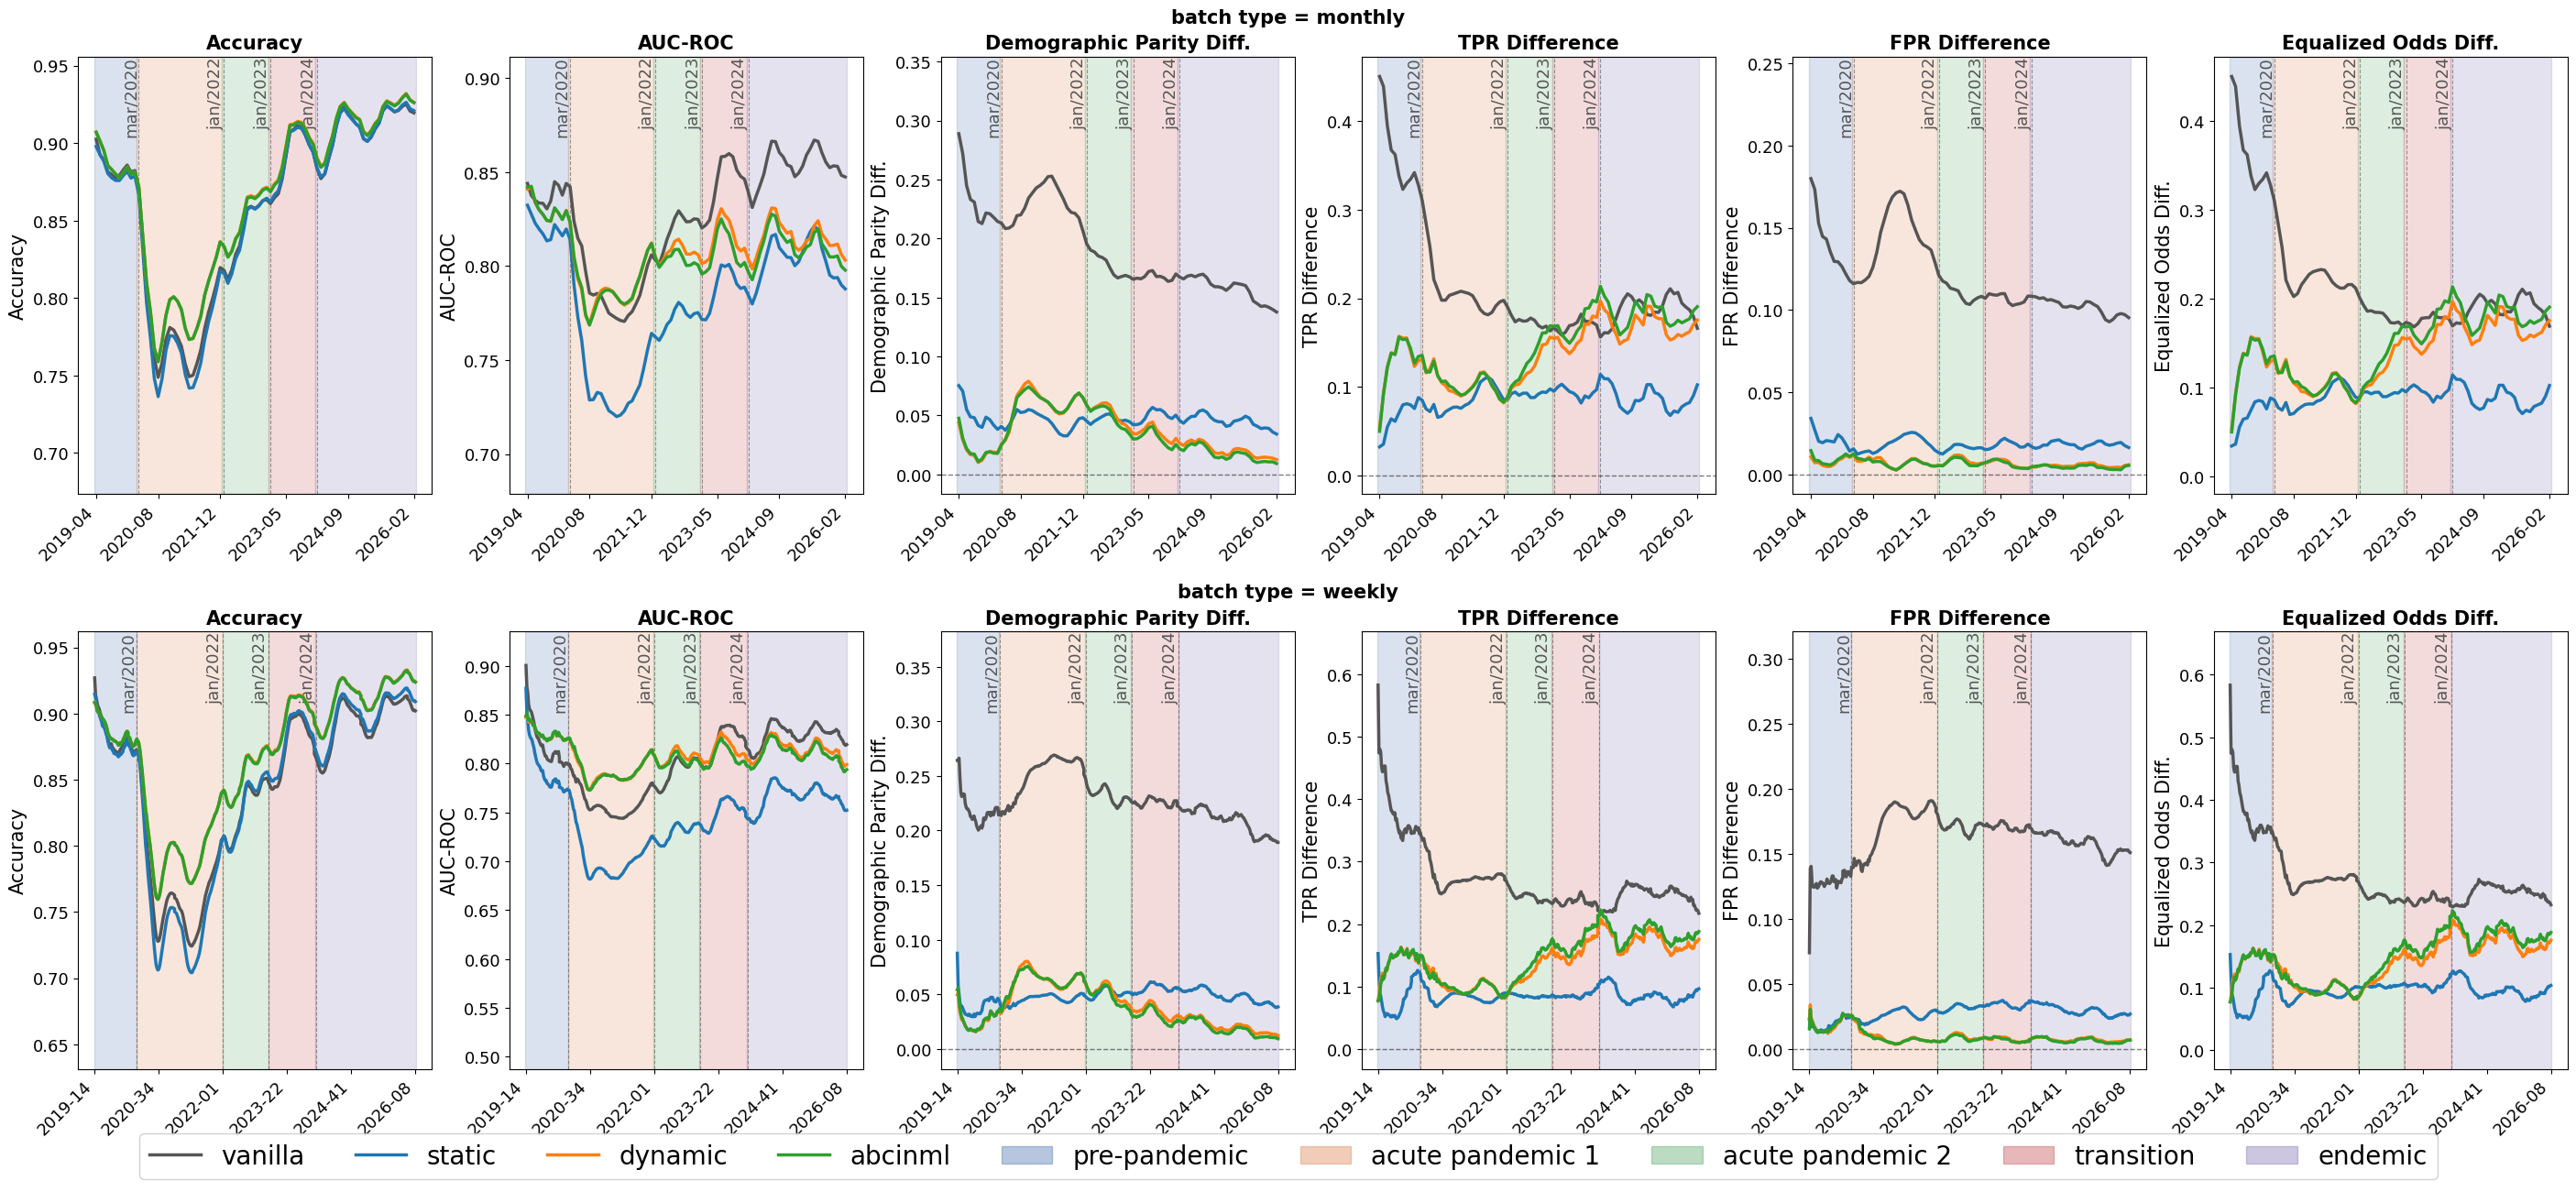

In [5]:
from metrics_utils import (
    _BASELINE_ORDER,
    _BASELINE_COLORS,
    _BATCH_FORMAT,
    _batch_to_datetime,
    _build_ma_series,
    _add_period_spans,
    _apply_bin_xticks,
)



def plot_baselines_row(axes, assessment_df, batch_type, moving_avg_window):
    """Replicate the logic of _generate_comparative_chart on one row of axes."""
    df = assessment_df.copy()
    df['batch_dt'] = _batch_to_datetime(df['batch'].astype(str).tolist(), batch_type)
    df = df.groupby(['baseline', 'batch', 'batch_dt'], as_index=False)[metric_cols].mean()

    present_baselines = [b for b in _BASELINE_ORDER if b in df['baseline'].unique()]

    common_dates = None
    for bt in present_baselines:
        dates = set(df[df['baseline'] == bt]['batch_dt'])
        common_dates = dates if common_dates is None else common_dates & dates
    common_dates = sorted(common_dates) if common_dates else []

    metric_ylims = {}
    for col, _ in _SNAPSHOT_METRICS:
        values = assessment_df[col].dropna()
        if len(values) == 0:
            continue
        vmin, vmax = values.min(), values.max()
        padding = (vmax - vmin) * 0.05
        metric_ylims[col] = (vmin - padding, vmax + padding)

    all_batch_labels = sorted(df['batch'].astype(str).unique())

    baseline_handles, period_handles = [], []
    for col_idx, (col, label) in enumerate(_SNAPSHOT_METRICS):
        ax = axes[col_idx]

        handles = _add_period_spans(ax, all_batch_labels, batch_type)
        if not period_handles:
            period_handles = handles

        if col in ('dp', 'tpr_diff', 'fpr_diff'):
            ax.axhline(y=0, color='black', linestyle='--', linewidth=1.0, alpha=0.5, zorder=2)

        for bt in present_baselines:
            sub = df[df['baseline'] == bt]
            ma = _build_ma_series(sub, col, moving_avg_window)
            ma = ma[ma.index.isin(common_dates)] if common_dates else ma

            fmt = _BATCH_FORMAT[batch_type]
            x_pos = [all_batch_labels.index(d.strftime(fmt)) for d in ma.index if d.strftime(fmt) in all_batch_labels]
            line, = ax.plot(
                x_pos, ma.values,
                color=_BASELINE_COLORS.get(bt, None),
                linewidth=2.5,
                label=bt,
                zorder=3,
            )
            if col_idx == 0:
                baseline_handles.append(line)

        ax.set_title(label, fontsize=15, fontweight='bold')
        ax.set_ylabel(label, fontsize=15)
        if col in metric_ylims:
            ax.set_ylim(metric_ylims[col])
        _apply_bin_xticks(ax, all_batch_labels)
        ax.tick_params(axis='x', labelsize=13)
        ax.tick_params(axis='y', labelsize=13)

    return baseline_handles, period_handles


fig = plt.figure(figsize=(28, 13), layout='constrained')
subfigs = fig.subfigures(2, 1)

rows = [
    ('monthly', lr_monthly_df, 5),
    ('weekly', lr_weekly_df, 20),
]

baseline_handles, period_handles = [], []
for subfig, (batch_type, df_row, ma_window) in zip(subfigs, rows):
    axes = subfig.subplots(1, len(_SNAPSHOT_METRICS))
    subfig.suptitle(f'batch type = {batch_type}', fontsize=15, fontweight='bold')
    bh, ph = plot_baselines_row(axes, df_row, batch_type, ma_window)
    if not baseline_handles:
        baseline_handles, period_handles = bh, ph


# Post-plot tweaks: span alpha (same as EDA fig1) and font of the vline labels
for ax in fig.axes:
    for patch in ax.patches:
        patch.set_alpha(0.20)
    for text in ax.texts:
        text.set_fontsize(13)

all_handles = baseline_handles + period_handles
legend_labels = [h.get_label() for h in all_handles]
leg = fig.legend(
    all_handles, legend_labels,
    loc='outside lower center', ncol=len(all_handles), fontsize=20, framealpha=0.9,
)

# Period swatches in the legend with the same alpha as the EDA fig1 legend
for legend_patch in leg.get_patches():
    legend_patch.set_alpha(0.4)

# Save the figure to src/notebooks/figures/results_overview/
fig_dir = ROOT / 'src' / 'notebooks' / 'figures' / 'results_overview'
fig_dir.mkdir(parents=True, exist_ok=True)
fig_path = fig_dir / 'baselines_comparison_lr.png'
fig.savefig(fig_path, dpi=120, bbox_inches='tight')

plt.show()

### ABCinML alpha analysis

Two views of the effect of `alpha` (weight of the current vs. anticipated reweighing) on the `abcinml` baseline, using the **monthly** batches:

1. **Metric vs Alpha (global)** — mean of each metric over all batches, per alpha; one line per model (logistic regression and xgboost), with dashed horizontal reference lines for `dynamic` and `static` (mean over the same batches as abcinml).
2. **Metric vs Alpha per epidemiological period** — logistic regression only; one line per period (`_PERIOD_SPANS`), showing how the optimal alpha changes between pre-pandemic, acute pandemic, transition and endemic.

Outputs saved to `src/notebooks/figures/results_overview/`.

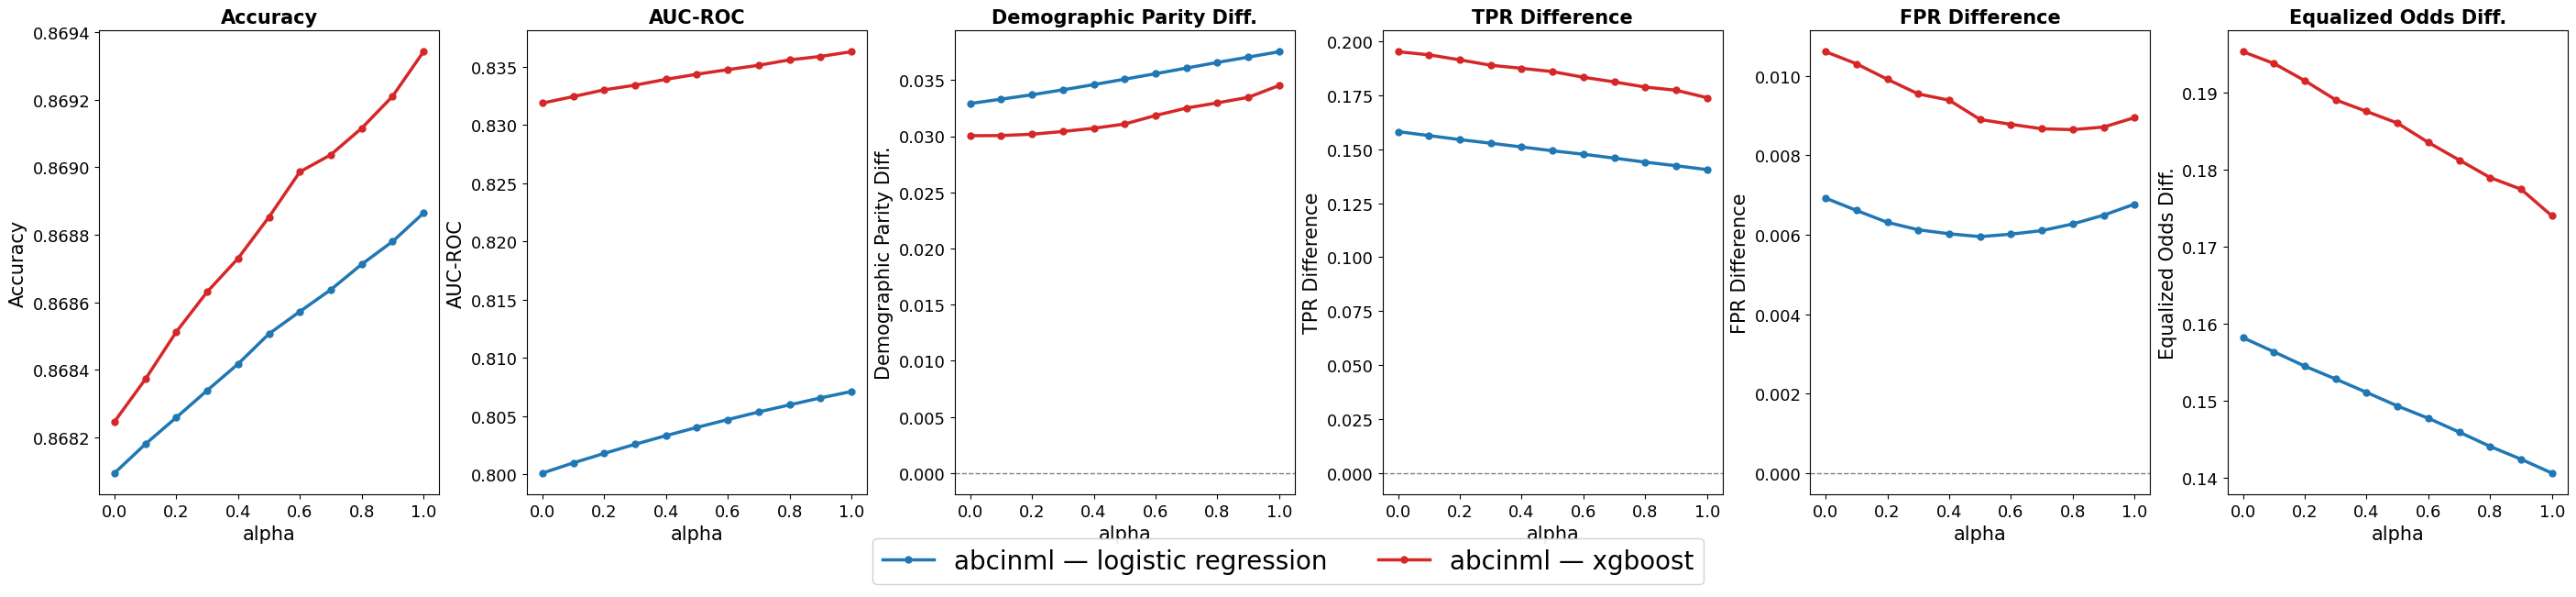

In [6]:
import numpy as np

MODEL_COLORS = {'logistic_regression': '#1f77b4', 'xgboost': '#d62728'}
MODEL_LABELS = {'logistic_regression': 'logistic regression', 'xgboost': 'xgboost'}

monthly_df = assessment_df[assessment_df['batch_type'] == 'monthly']

results_dir = ROOT / 'src' / 'notebooks' / 'figures' / 'results_overview'
results_dir.mkdir(parents=True, exist_ok=True)

# ── Chart 1: metric vs alpha, global mean over the batches ─────────────────
fig, axes = plt.subplots(1, len(_SNAPSHOT_METRICS), figsize=(28, 6.5), layout='constrained')

handles, labels = [], []
for col_idx, (col, label) in enumerate(_SNAPSHOT_METRICS):
    ax = axes[col_idx]

    for model in ['logistic_regression', 'xgboost']:
        sub = monthly_df[monthly_df['model_name'] == model]
        abc = sub[sub['baseline'] == 'abcinml']
        if abc.empty:
            continue
        color = MODEL_COLORS[model]

        curve = abc.groupby('alpha')[col].mean().sort_index()
        line, = ax.plot(curve.index, curve.values, color=color, linewidth=2.5,
                        marker='o', markersize=5, zorder=3)

        if col_idx == 0:
            handles.append(line)
            labels.append(f'abcinml — {MODEL_LABELS[model]}')

    if col in ('dp', 'tpr_diff', 'fpr_diff'):
        ax.axhline(y=0, color='black', linestyle='--', linewidth=1.0, alpha=0.5, zorder=1)

    ax.set_title(label, fontsize=15, fontweight='bold')
    ax.set_ylabel(label, fontsize=15)
    ax.set_xlabel('alpha', fontsize=15)
    ax.set_xticks(np.arange(0, 1.1, 0.2))
    ax.tick_params(axis='x', labelsize=13)
    ax.tick_params(axis='y', labelsize=13)

fig.legend(handles, labels, loc='outside lower center', ncol=len(handles), fontsize=20, framealpha=0.9)

out_path = results_dir / 'alpha_analysis_global.png'
fig.savefig(out_path, dpi=120, bbox_inches='tight')

plt.show()

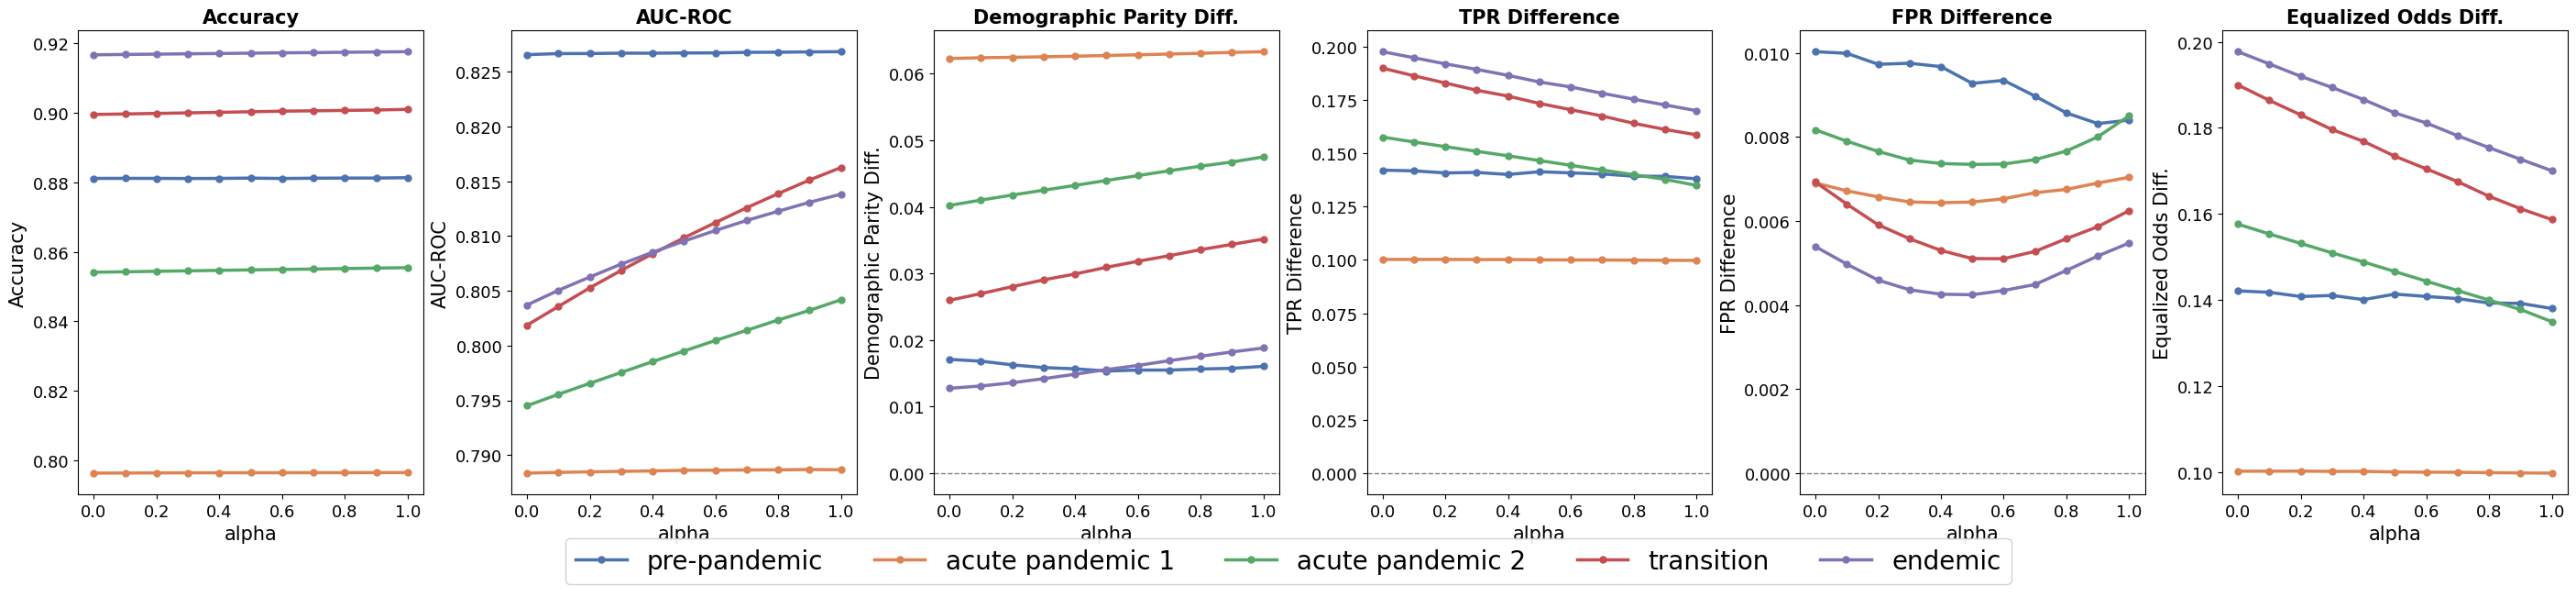

In [7]:
from metrics_utils import _PERIOD_SPANS

# ── Chart 2: metric vs alpha per epidemiological period (LR, monthly) ───────
lr_abc = monthly_df[
    (monthly_df['model_name'] == 'logistic_regression') & (monthly_df['baseline'] == 'abcinml')
].copy()
lr_abc['batch_dt'] = _batch_to_datetime(lr_abc['batch'].astype(str).tolist(), 'monthly')


def assign_period(dt):
    for start, end, name, color in _PERIOD_SPANS:
        if pd.Timestamp(start) <= dt < pd.Timestamp(end):
            return name
    return None


lr_abc['period'] = lr_abc['batch_dt'].map(assign_period)

fig, axes = plt.subplots(1, len(_SNAPSHOT_METRICS), figsize=(28, 6.5), layout='constrained')

handles, labels = [], []
for col_idx, (col, label) in enumerate(_SNAPSHOT_METRICS):
    ax = axes[col_idx]

    for start, end, name, color in _PERIOD_SPANS:
        sub = lr_abc[lr_abc['period'] == name]
        if sub.empty:
            continue
        curve = sub.groupby('alpha')[col].mean().sort_index()
        line, = ax.plot(curve.index, curve.values, color=color, linewidth=2.5,
                        marker='o', markersize=5, zorder=3)
        if col_idx == 0:
            handles.append(line)
            labels.append(name)

    if col in ('dp', 'tpr_diff', 'fpr_diff'):
        ax.axhline(y=0, color='black', linestyle='--', linewidth=1.0, alpha=0.5, zorder=1)

    ax.set_title(label, fontsize=15, fontweight='bold')
    ax.set_ylabel(label, fontsize=15)
    ax.set_xlabel('alpha', fontsize=15)
    ax.set_xticks(np.arange(0, 1.1, 0.2))
    ax.tick_params(axis='x', labelsize=13)
    ax.tick_params(axis='y', labelsize=13)

fig.legend(handles, labels, loc='outside lower center', ncol=len(handles), fontsize=20, framealpha=0.9)

out_path = results_dir / 'alpha_analysis_by_period_lr.png'
fig.savefig(out_path, dpi=120, bbox_inches='tight')

plt.show()

### Absolute rates per sensitive group — mean per baseline

Replicates the logic of `metrics_utils._generate_absolute_rates_chart` on the aggregated results (`absolute_results_df.csv`), filtering **logistic regression + monthly** and aggregating the rates by the **mean per `(baseline, batch)`** (collapsing alphas, techniques and windows). 4×2 grid: one row per baseline, TPR and FPR columns, with a 10-batch moving average and the lines of groups S0 (privileged, age < 65) and S1 (sensitive, age ≥ 65).

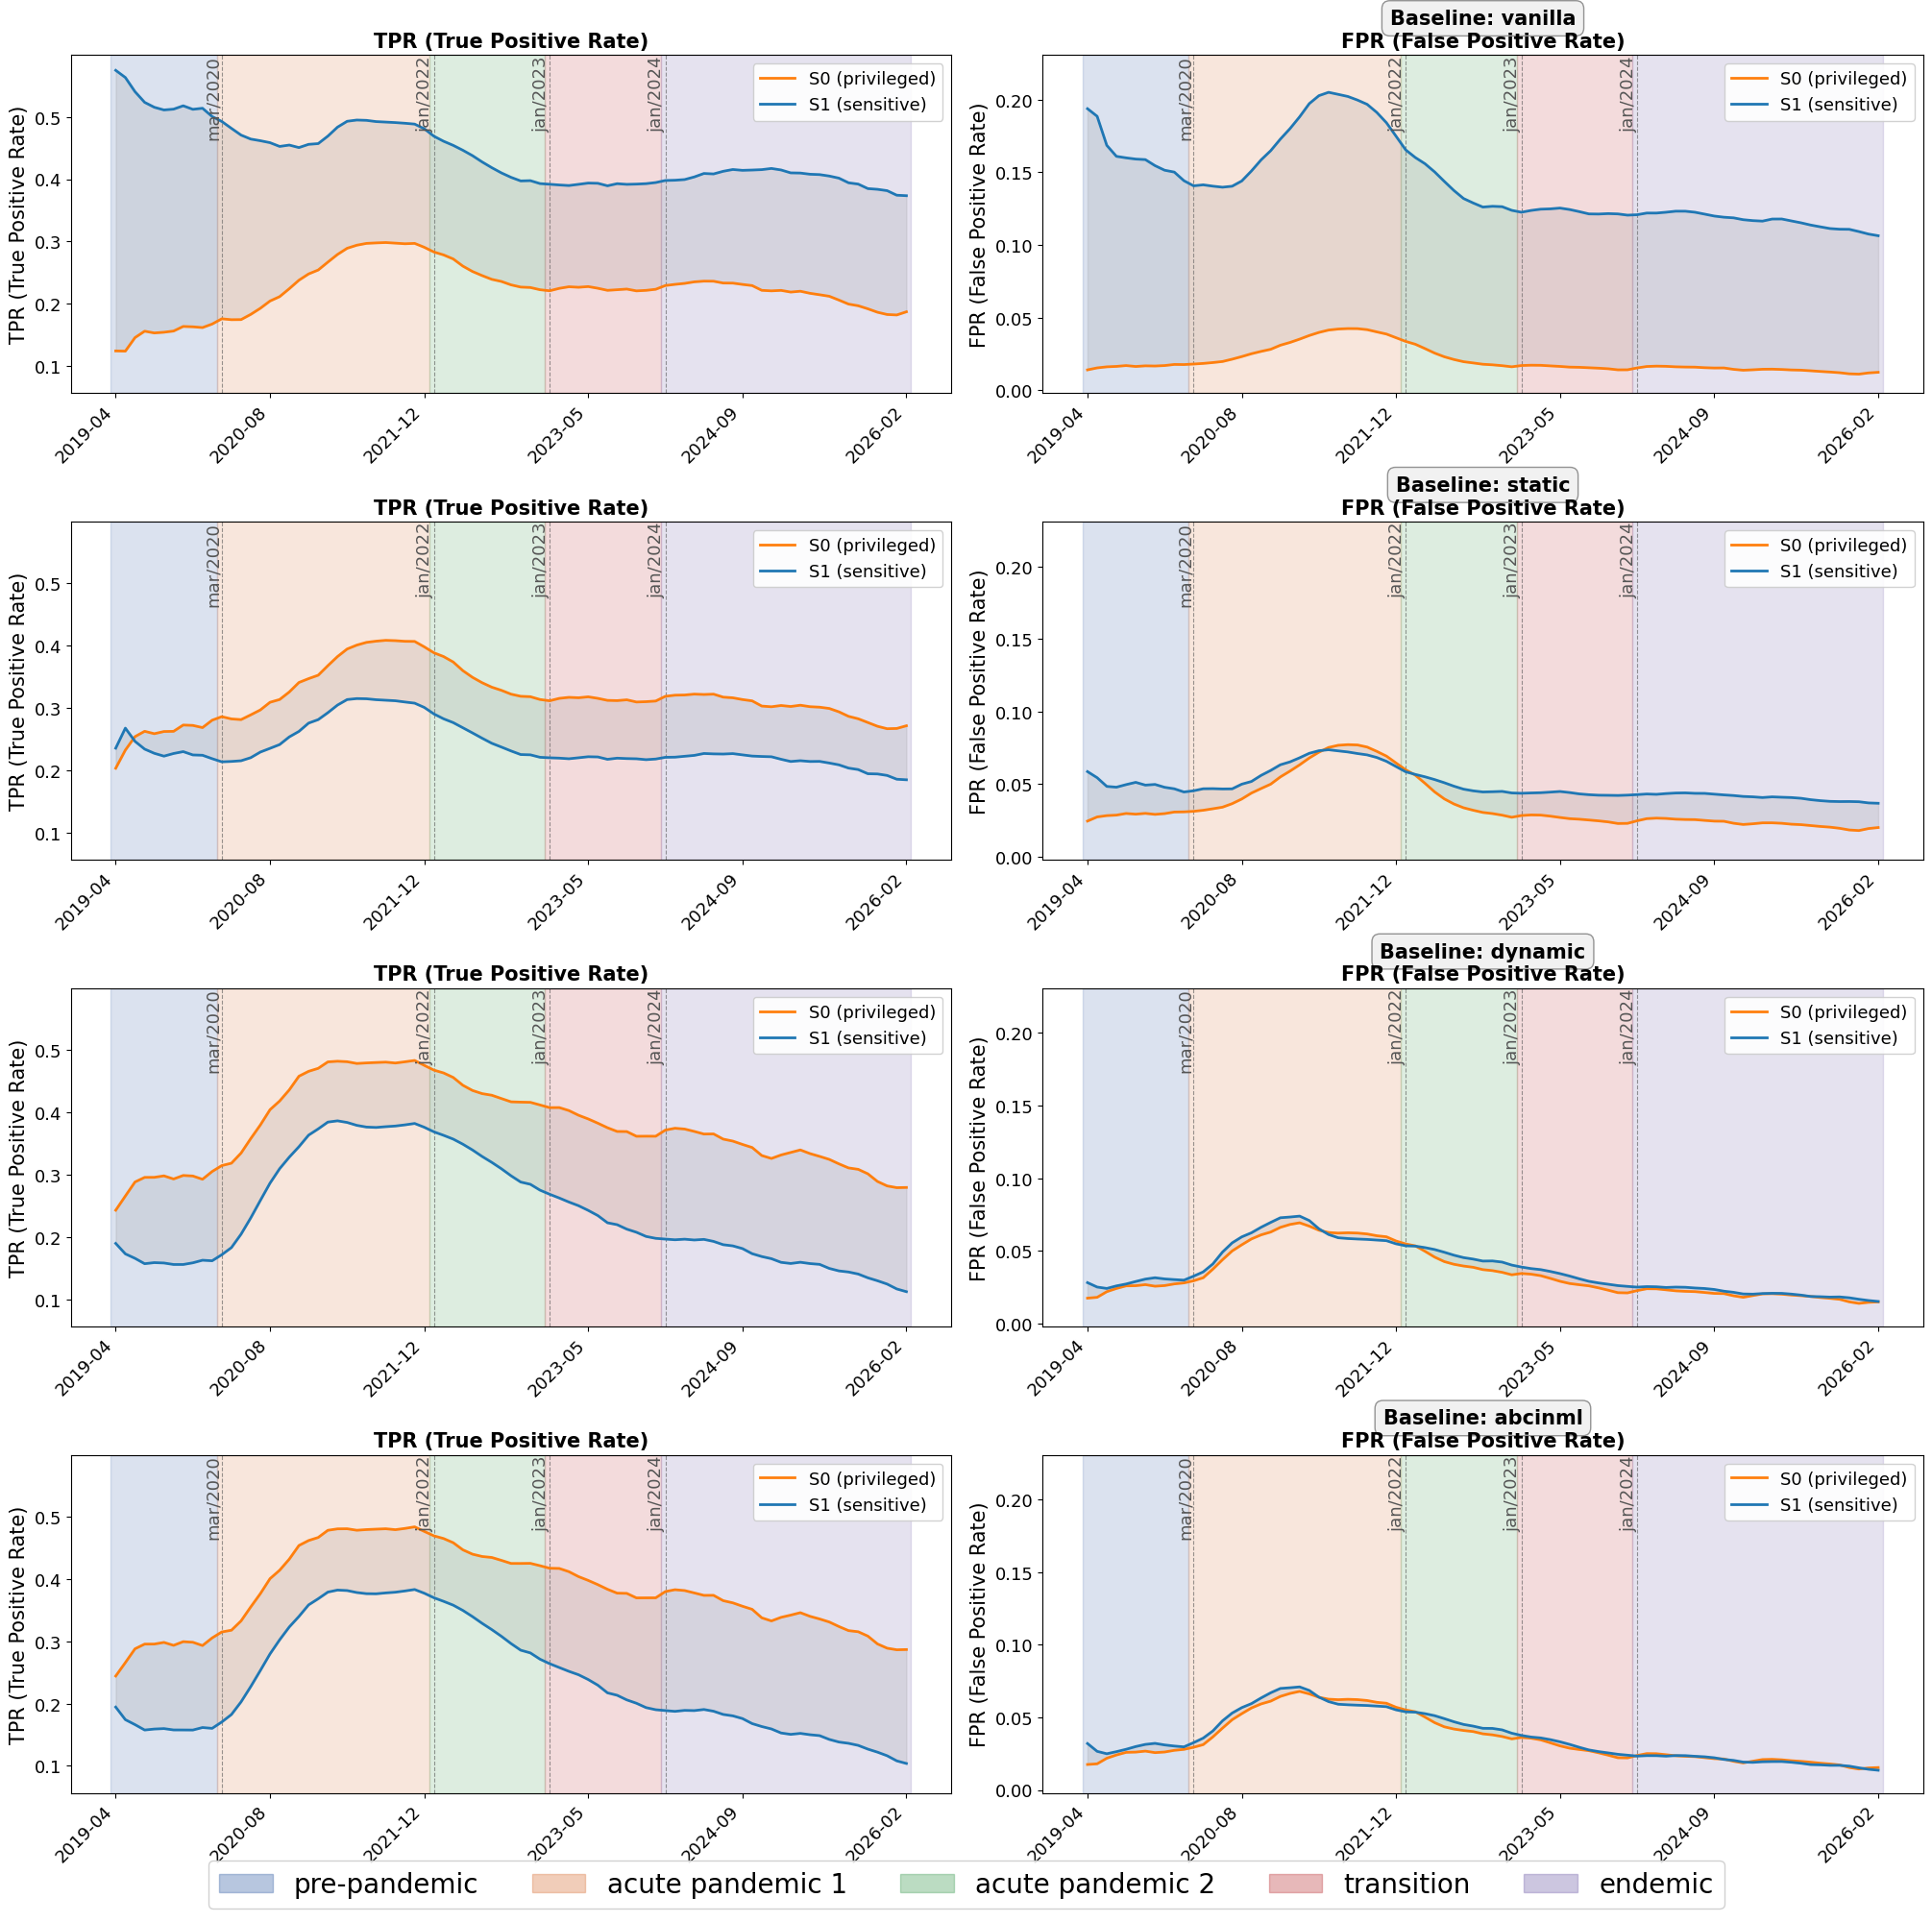

In [8]:
# Load and filter the absolute rates: LR + monthly
absolute_df = pd.read_csv(ROOT / 'src' / 'results' / 'all' / 'absolute_results_df.csv')

# Same filter as the assessment cell: Kamiran & Calders only (see the comment above)
absolute_df = absolute_df[absolute_df['fairness_correction'] == 'kamiran_rw'].copy()

# Fix the forecasting technique to 'sma' (ema/oracle are left for separate analyses)
absolute_df = absolute_df[absolute_df['forecasting_technique'] == 'sma'].copy()
abs_lr = absolute_df[
    (absolute_df['model_name'] == 'logistic_regression')
    & (absolute_df['batch_type'] == 'monthly')
].copy()

_MA_WINDOW = 10  # pipeline default for monthly
_S0_COLOR = '#ff7f0e'
_S1_COLOR = '#1f77b4'

rate_cols = ['tpr_S0', 'fpr_S0', 'tpr_S1', 'fpr_S1']
abs_lr['batch_dt'] = _batch_to_datetime(abs_lr['batch'].astype(str).tolist(), 'monthly')

# Mean per (baseline, batch): collapses alphas, forecasting techniques and windows
abs_mean = abs_lr.groupby(['baseline', 'batch', 'batch_dt'], as_index=False)[rate_cols].mean()

present_baselines = [b for b in _BASELINE_ORDER if b in abs_mean['baseline'].unique()]
n_rows = len(present_baselines)
all_batch_labels = sorted(abs_mean['batch'].astype(str).unique())

tpr_values = pd.concat([abs_mean['tpr_S0'], abs_mean['tpr_S1']])
tpr_pad = (tpr_values.max() - tpr_values.min()) * 0.05
tpr_ylim = (tpr_values.min() - tpr_pad, tpr_values.max() + tpr_pad)

fpr_values = pd.concat([abs_mean['fpr_S0'], abs_mean['fpr_S1']])
fpr_pad = (fpr_values.max() - fpr_values.min()) * 0.05
fpr_ylim = (fpr_values.min() - fpr_pad, fpr_values.max() + fpr_pad)

_RATE_PAIRS = [
    ('tpr_S0', 'tpr_S1', 'TPR (True Positive Rate)', tpr_ylim),
    ('fpr_S0', 'fpr_S1', 'FPR (False Positive Rate)', fpr_ylim),
]

fig, axes = plt.subplots(n_rows, 2, figsize=(20, 5 * n_rows), squeeze=False, layout='constrained')

period_handles = []
for row, bt in enumerate(present_baselines):
    sub = abs_mean[abs_mean['baseline'] == bt].sort_values('batch_dt').reset_index(drop=True)
    x_str = sub['batch'].astype(str).tolist()
    x_idx = [all_batch_labels.index(b) for b in x_str if b in all_batch_labels]

    for col_idx, (col_s0, col_s1, col_label, ylim) in enumerate(_RATE_PAIRS):
        ax = axes[row][col_idx]

        handles = _add_period_spans(ax, all_batch_labels, 'monthly')
        if not period_handles:
            period_handles = handles

        ma_s0 = sub[col_s0].rolling(window=_MA_WINDOW, min_periods=1).mean().values
        ma_s1 = sub[col_s1].rolling(window=_MA_WINDOW, min_periods=1).mean().values

        line_s0, = ax.plot(x_idx, ma_s0, color=_S0_COLOR, linewidth=2.0, label='S0 (privileged)')
        line_s1, = ax.plot(x_idx, ma_s1, color=_S1_COLOR, linewidth=2.0, label='S1 (sensitive)')
        ax.fill_between(x_idx, ma_s0, ma_s1, alpha=0.15, color='gray')

        ax.set_title(col_label, fontsize=15, fontweight='bold')
        ax.set_ylabel(col_label, fontsize=15)
        ax.set_ylim(ylim)
        # Inner legend with the group lines only (periods go in the main legend)
        ax.legend(handles=[line_s0, line_s1], fontsize=13, framealpha=0.9)
        _apply_bin_xticks(ax, all_batch_labels)
        ax.tick_params(axis='x', labelsize=13)
        ax.tick_params(axis='y', labelsize=13)

    # Baseline label above the row (right column, as in the pipeline)
    axes[row][1].annotate(
        f'Baseline: {bt}',
        xy=(0.5, 1.08),
        xycoords='axes fraction',
        ha='center',
        va='bottom',
        fontsize=15,
        fontweight='bold',
        bbox=dict(boxstyle='round,pad=0.4', facecolor='#f0f0f0', edgecolor='#888888', alpha=0.9),
    )


# Post-plot tweaks (visual identity of this notebook): span alpha and font of the
# vline labels — only the date texts (they contain '/'), keeping the annotations
for ax in fig.axes:
    for patch in ax.patches:
        patch.set_alpha(0.20)
    for text in ax.texts:
        if '/' in text.get_text():
            text.set_fontsize(13)

period_labels = [h.get_label() for h in period_handles]
leg = fig.legend(
    period_handles, period_labels,
    loc='outside lower center', ncol=len(period_handles), fontsize=20, framealpha=0.9,
)
for legend_patch in leg.get_patches():
    legend_patch.set_alpha(0.4)

out_path = results_dir / 'absolute_rates_by_group_lr.png'
fig.savefig(out_path, dpi=120, bbox_inches='tight')

plt.show()

## XGBoost versions

The same charts generated above, now for the **xgboost** model (the global *Metric vs Alpha* chart already has both model lines, so it is not repeated):

1. Comparison of the 4 baselines — monthly and weekly
2. Metric vs Alpha per epidemiological period
3. Absolute TPR/FPR rates per sensitive group

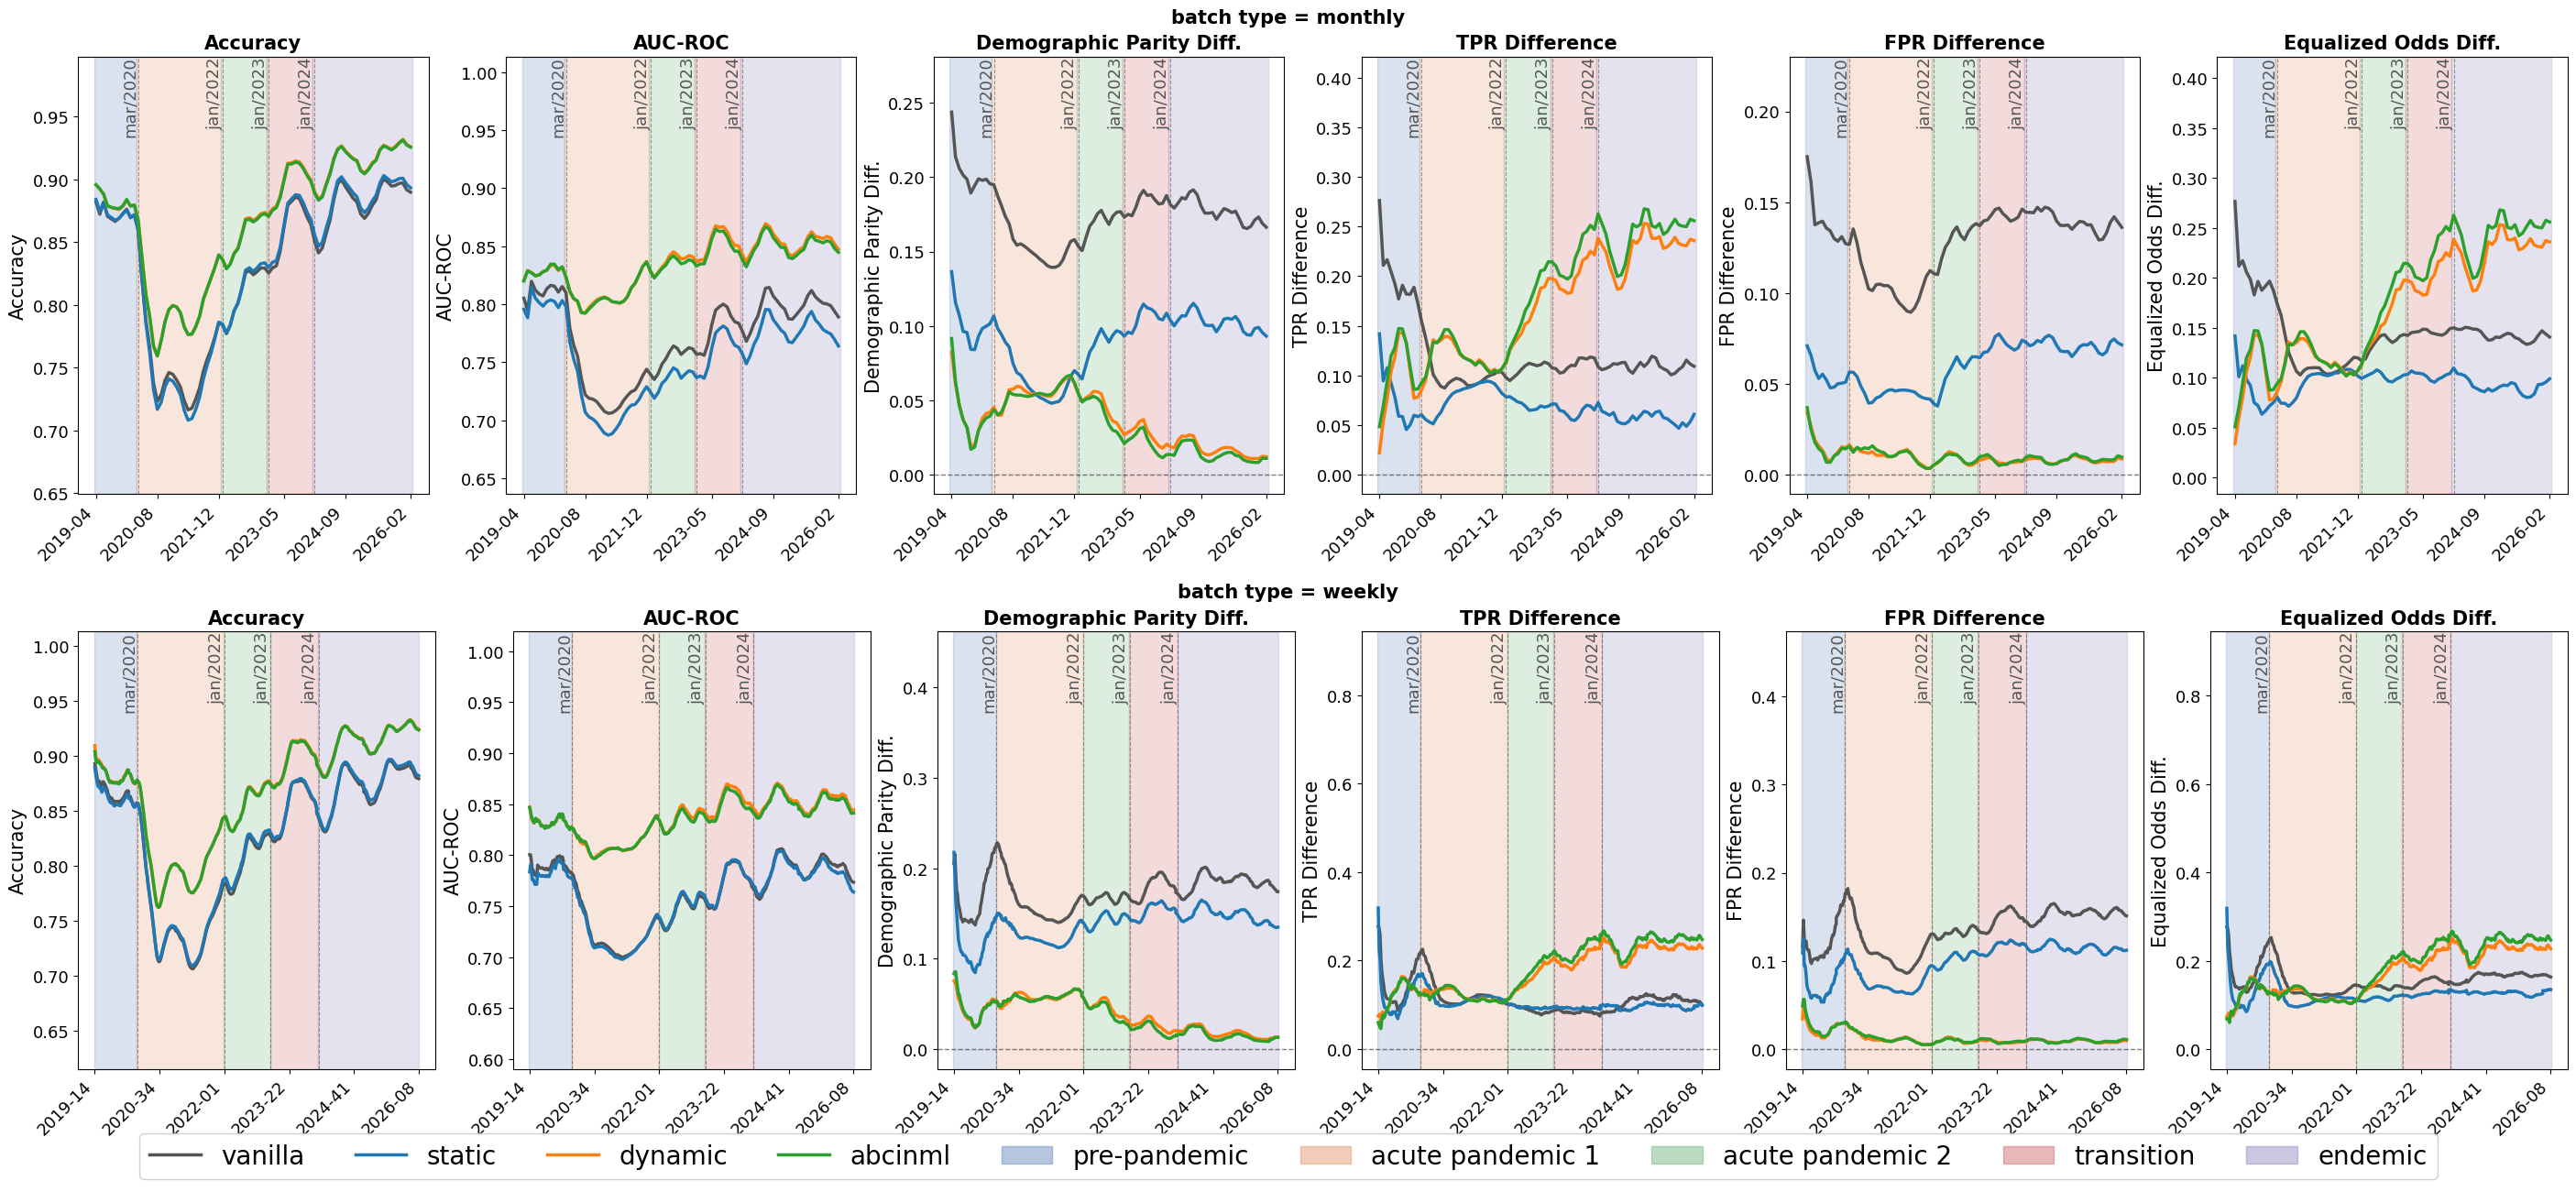

In [9]:
# ── XGBoost: comparison of the 4 baselines (monthly + weekly) ──────────────
xgb_df = assessment_df[assessment_df['model_name'] == 'xgboost']
xgb_monthly_df = xgb_df[xgb_df['batch_type'] == 'monthly'].copy()
xgb_weekly_df = xgb_df[xgb_df['batch_type'] == 'weekly'].copy()

fig = plt.figure(figsize=(28, 13), layout='constrained')
subfigs = fig.subfigures(2, 1)

rows = [
    ('monthly', xgb_monthly_df, 5),
    ('weekly', xgb_weekly_df, 20),
]

baseline_handles, period_handles = [], []
for subfig, (batch_type, df_row, ma_window) in zip(subfigs, rows):
    axes = subfig.subplots(1, len(_SNAPSHOT_METRICS))
    subfig.suptitle(f'batch type = {batch_type}', fontsize=15, fontweight='bold')
    bh, ph = plot_baselines_row(axes, df_row, batch_type, ma_window)
    if not baseline_handles:
        baseline_handles, period_handles = bh, ph


# Post-plot tweaks: span alpha and font of the vline labels
for ax in fig.axes:
    for patch in ax.patches:
        patch.set_alpha(0.20)
    for text in ax.texts:
        text.set_fontsize(13)

all_handles = baseline_handles + period_handles
legend_labels = [h.get_label() for h in all_handles]
leg = fig.legend(
    all_handles, legend_labels,
    loc='outside lower center', ncol=len(all_handles), fontsize=20, framealpha=0.9,
)
for legend_patch in leg.get_patches():
    legend_patch.set_alpha(0.4)

fig_path = results_dir / 'baselines_comparison_xgboost.png'
fig.savefig(fig_path, dpi=120, bbox_inches='tight')

plt.show()

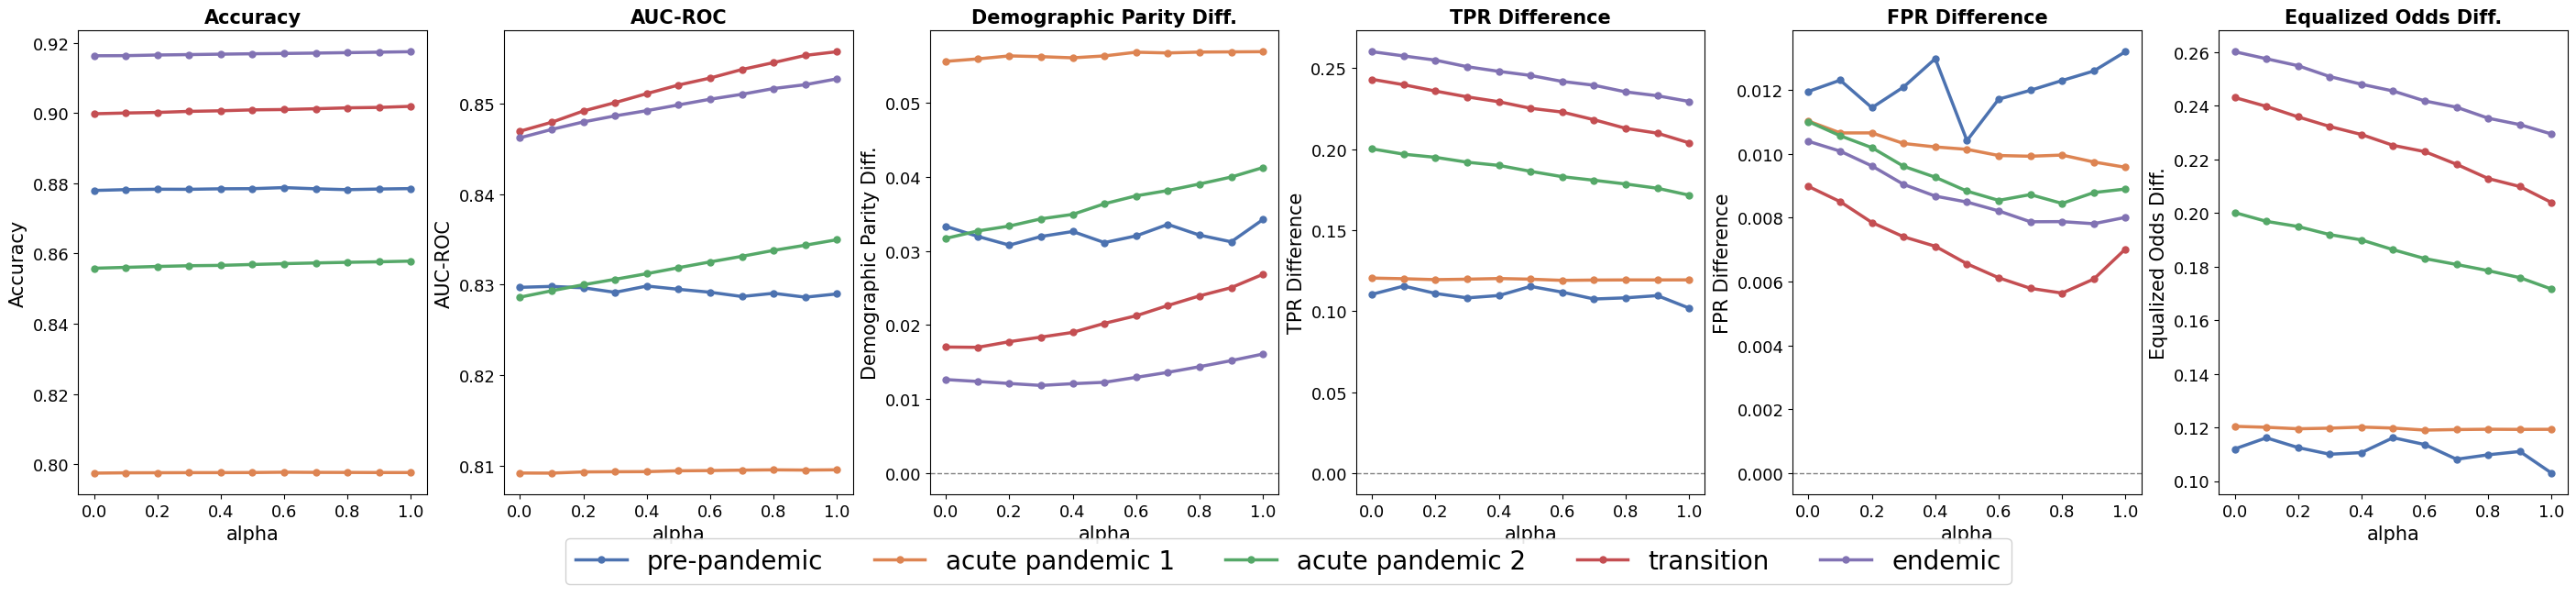

In [10]:
# ── XGBoost: metric vs alpha per epidemiological period (monthly) ──────────
xgb_abc = monthly_df[
    (monthly_df['model_name'] == 'xgboost') & (monthly_df['baseline'] == 'abcinml')
].copy()
xgb_abc['batch_dt'] = _batch_to_datetime(xgb_abc['batch'].astype(str).tolist(), 'monthly')
xgb_abc['period'] = xgb_abc['batch_dt'].map(assign_period)

fig, axes = plt.subplots(1, len(_SNAPSHOT_METRICS), figsize=(28, 6.5), layout='constrained')

handles, labels = [], []
for col_idx, (col, label) in enumerate(_SNAPSHOT_METRICS):
    ax = axes[col_idx]

    for start, end, name, color in _PERIOD_SPANS:
        sub = xgb_abc[xgb_abc['period'] == name]
        if sub.empty:
            continue
        curve = sub.groupby('alpha')[col].mean().sort_index()
        line, = ax.plot(curve.index, curve.values, color=color, linewidth=2.5,
                        marker='o', markersize=5, zorder=3)
        if col_idx == 0:
            handles.append(line)
            labels.append(name)

    if col in ('dp', 'tpr_diff', 'fpr_diff'):
        ax.axhline(y=0, color='black', linestyle='--', linewidth=1.0, alpha=0.5, zorder=1)

    ax.set_title(label, fontsize=15, fontweight='bold')
    ax.set_ylabel(label, fontsize=15)
    ax.set_xlabel('alpha', fontsize=15)
    ax.set_xticks(np.arange(0, 1.1, 0.2))
    ax.tick_params(axis='x', labelsize=13)
    ax.tick_params(axis='y', labelsize=13)

fig.legend(handles, labels, loc='outside lower center', ncol=len(handles), fontsize=20, framealpha=0.9)

out_path = results_dir / 'alpha_analysis_by_period_xgboost.png'
fig.savefig(out_path, dpi=120, bbox_inches='tight')

plt.show()

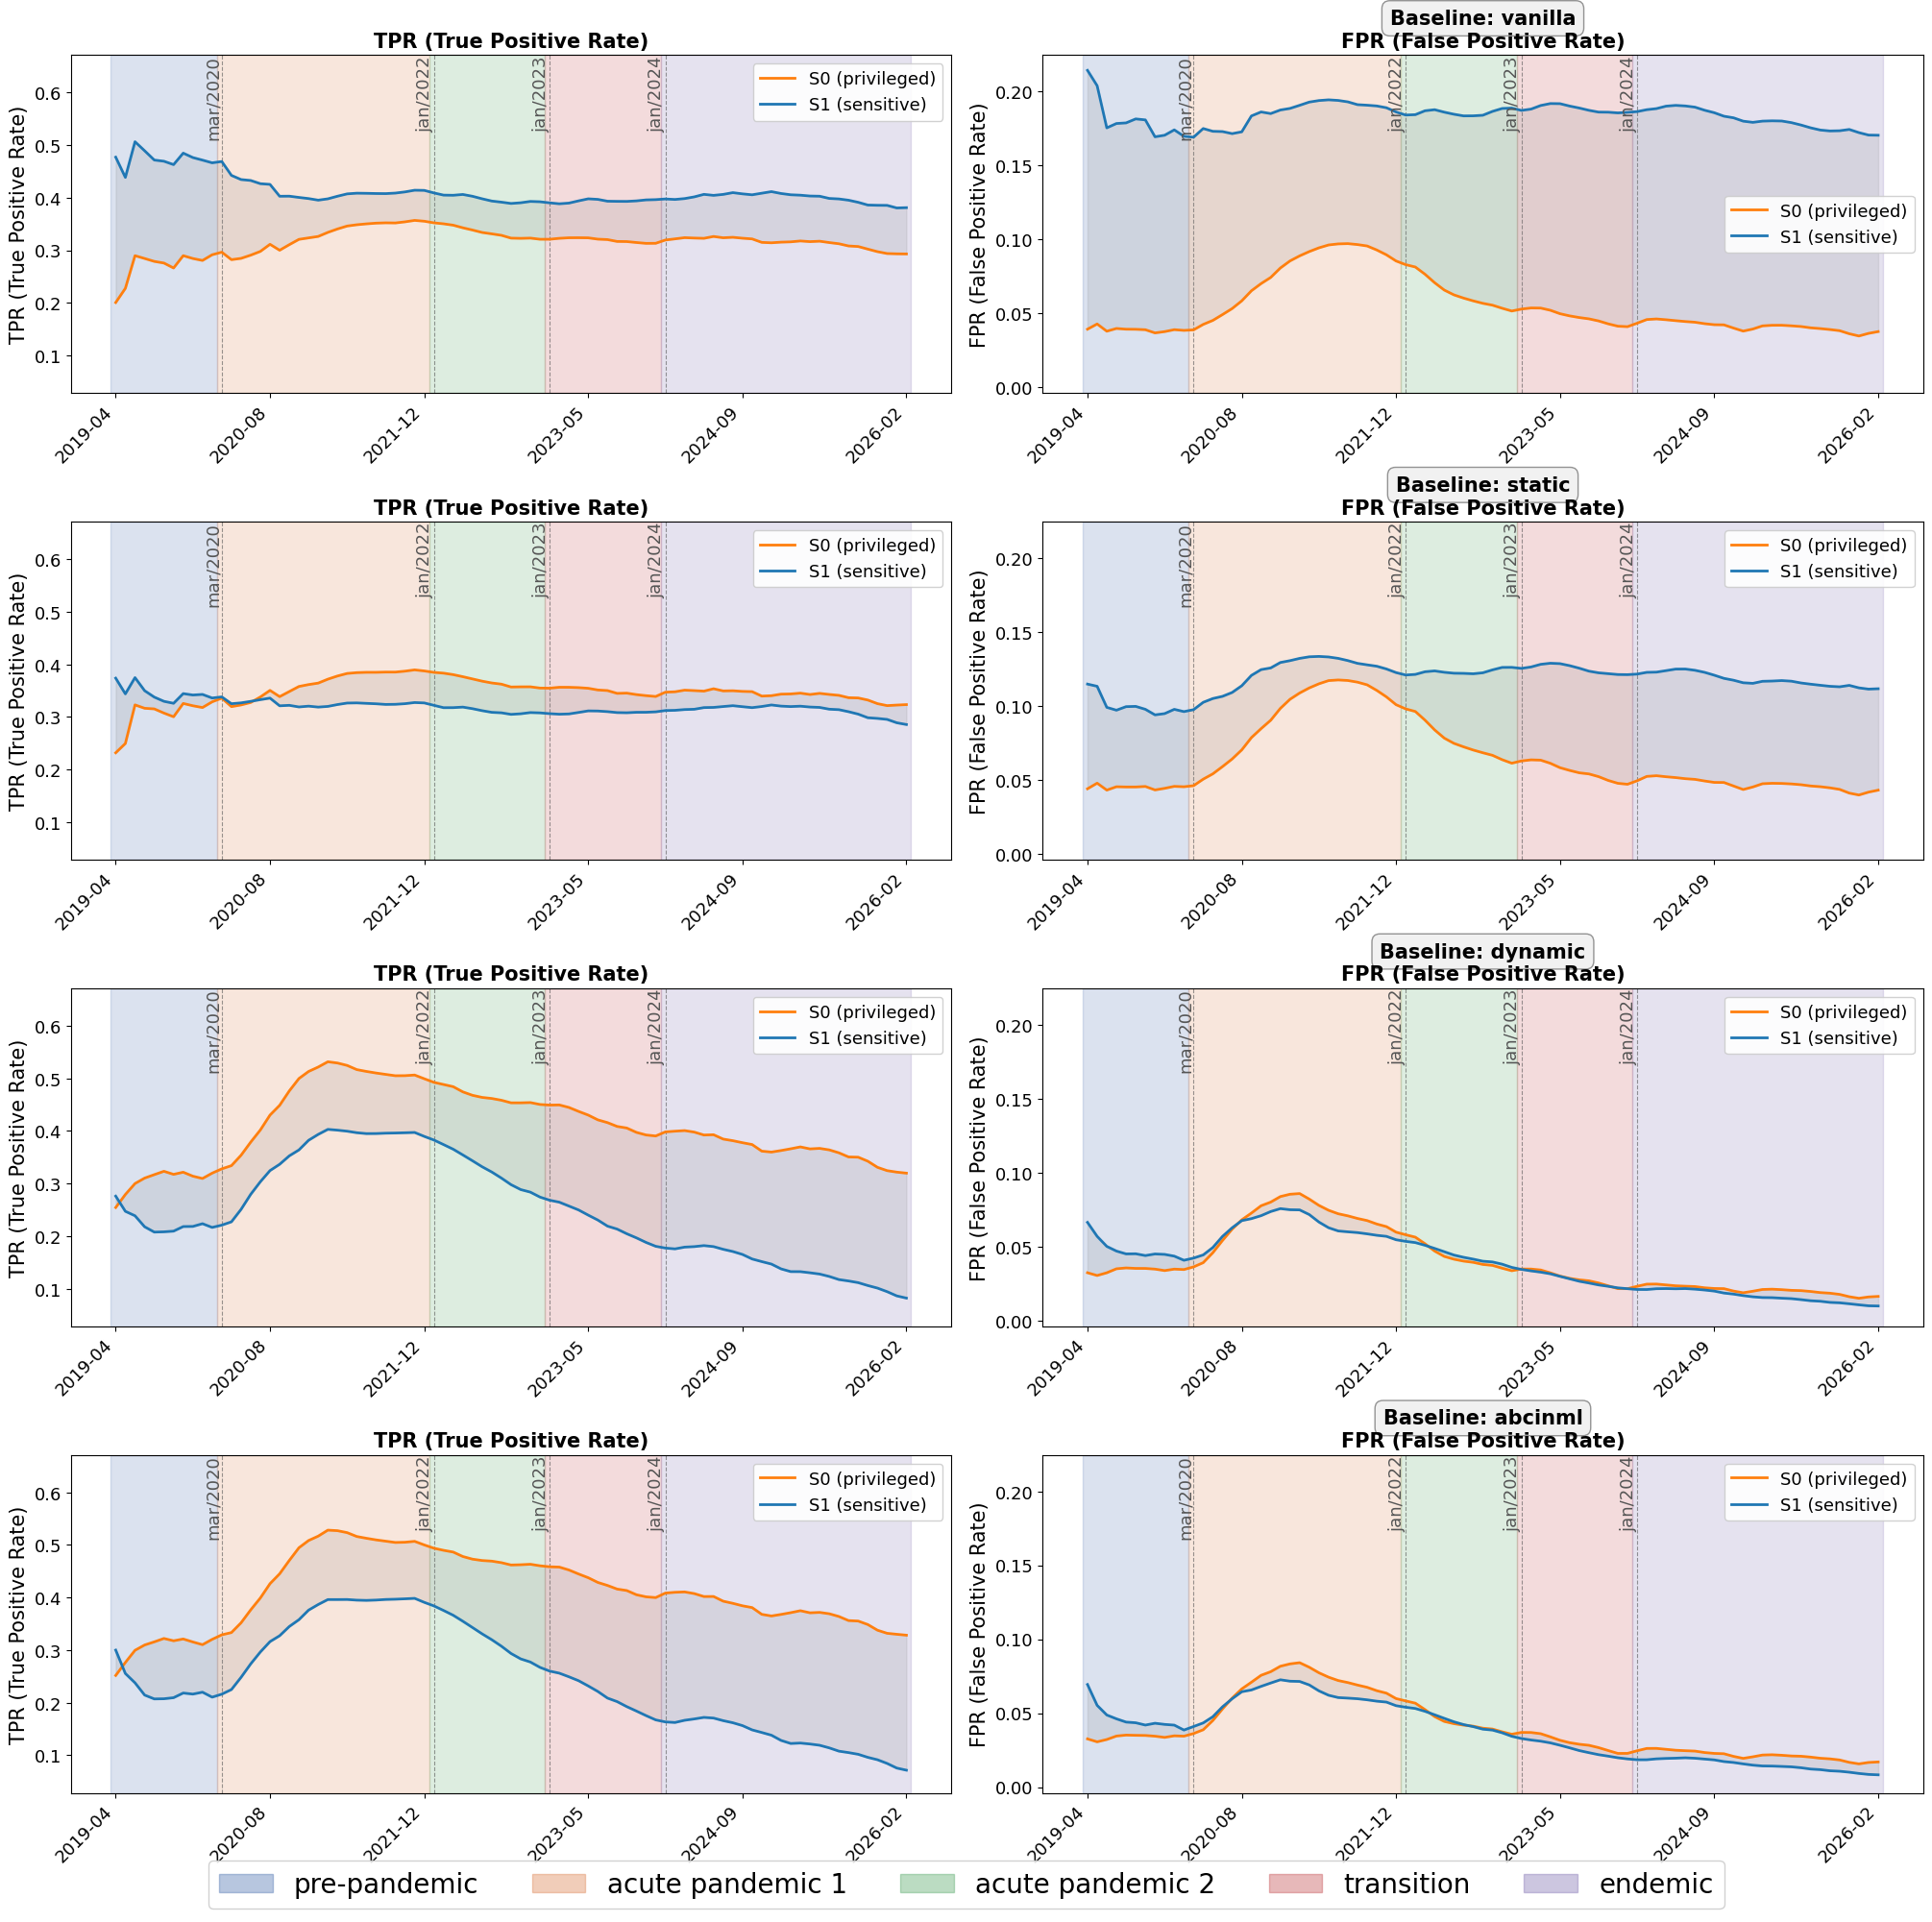

In [11]:
# ── XGBoost: absolute TPR/FPR rates per sensitive group (monthly) ──────────
abs_xgb = absolute_df[
    (absolute_df['model_name'] == 'xgboost')
    & (absolute_df['batch_type'] == 'monthly')
].copy()

abs_xgb['batch_dt'] = _batch_to_datetime(abs_xgb['batch'].astype(str).tolist(), 'monthly')
abs_mean = abs_xgb.groupby(['baseline', 'batch', 'batch_dt'], as_index=False)[rate_cols].mean()

present_baselines = [b for b in _BASELINE_ORDER if b in abs_mean['baseline'].unique()]
n_rows = len(present_baselines)
all_batch_labels = sorted(abs_mean['batch'].astype(str).unique())

tpr_values = pd.concat([abs_mean['tpr_S0'], abs_mean['tpr_S1']])
tpr_pad = (tpr_values.max() - tpr_values.min()) * 0.05
tpr_ylim = (tpr_values.min() - tpr_pad, tpr_values.max() + tpr_pad)

fpr_values = pd.concat([abs_mean['fpr_S0'], abs_mean['fpr_S1']])
fpr_pad = (fpr_values.max() - fpr_values.min()) * 0.05
fpr_ylim = (fpr_values.min() - fpr_pad, fpr_values.max() + fpr_pad)

_RATE_PAIRS = [
    ('tpr_S0', 'tpr_S1', 'TPR (True Positive Rate)', tpr_ylim),
    ('fpr_S0', 'fpr_S1', 'FPR (False Positive Rate)', fpr_ylim),
]

fig, axes = plt.subplots(n_rows, 2, figsize=(20, 5 * n_rows), squeeze=False, layout='constrained')

period_handles = []
for row, bt in enumerate(present_baselines):
    sub = abs_mean[abs_mean['baseline'] == bt].sort_values('batch_dt').reset_index(drop=True)
    x_str = sub['batch'].astype(str).tolist()
    x_idx = [all_batch_labels.index(b) for b in x_str if b in all_batch_labels]

    for col_idx, (col_s0, col_s1, col_label, ylim) in enumerate(_RATE_PAIRS):
        ax = axes[row][col_idx]

        handles = _add_period_spans(ax, all_batch_labels, 'monthly')
        if not period_handles:
            period_handles = handles

        ma_s0 = sub[col_s0].rolling(window=_MA_WINDOW, min_periods=1).mean().values
        ma_s1 = sub[col_s1].rolling(window=_MA_WINDOW, min_periods=1).mean().values

        line_s0, = ax.plot(x_idx, ma_s0, color=_S0_COLOR, linewidth=2.0, label='S0 (privileged)')
        line_s1, = ax.plot(x_idx, ma_s1, color=_S1_COLOR, linewidth=2.0, label='S1 (sensitive)')
        ax.fill_between(x_idx, ma_s0, ma_s1, alpha=0.15, color='gray')

        ax.set_title(col_label, fontsize=15, fontweight='bold')
        ax.set_ylabel(col_label, fontsize=15)
        ax.set_ylim(ylim)
        ax.legend(handles=[line_s0, line_s1], fontsize=13, framealpha=0.9)
        _apply_bin_xticks(ax, all_batch_labels)
        ax.tick_params(axis='x', labelsize=13)
        ax.tick_params(axis='y', labelsize=13)

    axes[row][1].annotate(
        f'Baseline: {bt}',
        xy=(0.5, 1.08),
        xycoords='axes fraction',
        ha='center',
        va='bottom',
        fontsize=15,
        fontweight='bold',
        bbox=dict(boxstyle='round,pad=0.4', facecolor='#f0f0f0', edgecolor='#888888', alpha=0.9),
    )


for ax in fig.axes:
    for patch in ax.patches:
        patch.set_alpha(0.20)
    for text in ax.texts:
        if '/' in text.get_text():
            text.set_fontsize(13)

period_labels = [h.get_label() for h in period_handles]
leg = fig.legend(
    period_handles, period_labels,
    loc='outside lower center', ncol=len(period_handles), fontsize=20, framealpha=0.9,
)
for legend_patch in leg.get_patches():
    legend_patch.set_alpha(0.4)

out_path = results_dir / 'absolute_rates_by_group_xgboost.png'
fig.savefig(out_path, dpi=120, bbox_inches='tight')

plt.show()

## Pivot table — mean TPR/FPR per baseline and group

Compact alternative to the absolute rates chart (too large for a paper). For each model, a pivot table with the **mean** TPR and FPR (in %) per baseline, split into groups S0 (privileged, age < 65) and S1 (sensitive, age ≥ 65). Same aggregation as the charts: mean per `(baseline, batch)` over the **monthly** batches, then mean over the batches. Saved as images to `src/notebooks/figures/results_overview/`.

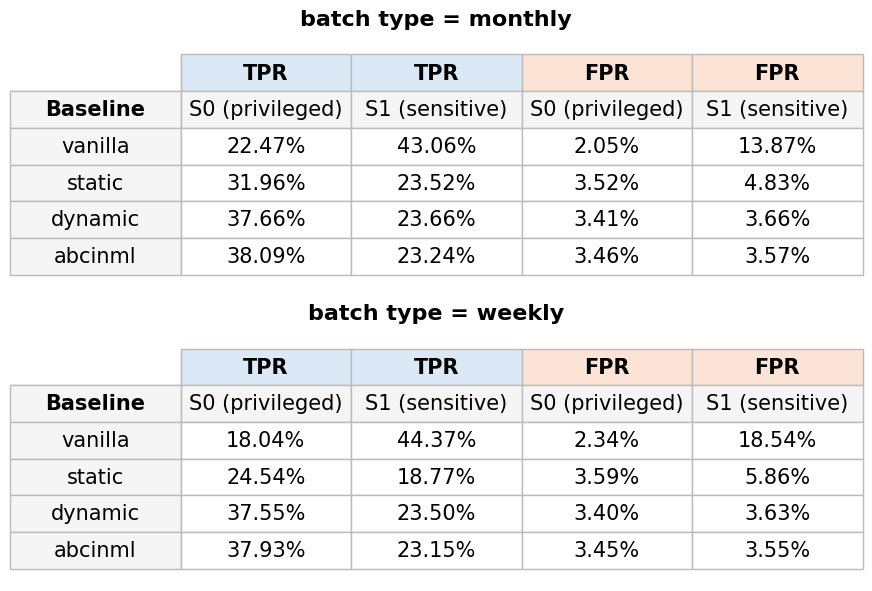

Metric               TPR                            FPR               
Group    S0 (privileged) S1 (sensitive) S0 (privileged) S1 (sensitive)
Baseline                                                              
vanilla            22.47          43.06            2.05          13.87
static             31.96          23.52            3.52           4.83
dynamic            37.66          23.66            3.41           3.66
abcinml            38.09          23.24            3.46           3.57

In [12]:
def absolute_rates_pivot(model_name, batch_type, as_percent=True):
    """Pivot: rows = baseline, columns = (TPR/FPR) × (S0/S1), mean over the batches."""
    sub = absolute_df[
        (absolute_df['model_name'] == model_name)
        & (absolute_df['batch_type'] == batch_type)
    ]
    # mean per (baseline, batch), then mean over the batches
    per_batch = sub.groupby(['baseline', 'batch'], as_index=False)[rate_cols].mean()
    agg = (
        per_batch.groupby('baseline')[rate_cols].mean()
        .reindex([b for b in _BASELINE_ORDER if b in per_batch['baseline'].unique()])
    )
    piv = pd.DataFrame({
        ('TPR', 'S0 (privileged)'): agg['tpr_S0'],
        ('TPR', 'S1 (sensitive)'): agg['tpr_S1'],
        ('FPR', 'S0 (privileged)'): agg['fpr_S0'],
        ('FPR', 'S1 (sensitive)'): agg['fpr_S1'],
    })
    piv.columns = pd.MultiIndex.from_tuples(piv.columns, names=['Metric', 'Group'])
    piv.index.name = 'Baseline'
    if as_percent:
        piv = piv * 100
    return piv.round(2)


def _draw_pivot_table(ax, piv, subtitle):
    """Draw a pivot (2-level MultiIndex columns) as a table on an axis, with a subtitle."""
    ax.axis('off')
    ax.set_title(subtitle, fontsize=16, fontweight='bold', pad=12)

    header_metric = [''] + [m for m, _ in piv.columns]           # row 1: TPR/FPR
    header_group = ['Baseline'] + [g for _, g in piv.columns]    # row 2: Baseline / S0 / S1
    body = [[idx] + [f'{v:.2f}%' for v in row] for idx, row in zip(piv.index, piv.values)]
    table_data = [header_metric, header_group] + body

    tbl = ax.table(cellText=table_data, cellLoc='center', loc='center')
    tbl.auto_set_font_size(False)
    tbl.set_fontsize(15)
    tbl.scale(1, 2.2)

    metric_fill = {'TPR': '#dbe9f6', 'FPR': '#fbe3d6'}
    light_gray = '#f5f5f5'
    for (r, c), cell in tbl.get_celld().items():
        cell.set_edgecolor('#bbbbbb')
        if r == 0:  # metric row: TPR/FPR in bold
            txt = cell.get_text().get_text()
            cell.set_facecolor(metric_fill.get(txt, 'white'))
            if txt:
                cell.get_text().set_fontweight('bold')
            if c == 0:
                cell.set_facecolor('white')
                cell.visible_edges = 'BR'
        elif r == 1:  # header: only 'Baseline' in bold; groups normal, light gray background
            cell.set_facecolor(light_gray)
            if c == 0:
                cell.get_text().set_fontweight('bold')
        elif c == 0:  # baseline column (values): light gray background, no bold
            cell.set_facecolor(light_gray)


def save_pivot_image(model_name, out_path):
    """One image with two stacked pivots: monthly (top) and weekly (bottom)."""
    piv_monthly = absolute_rates_pivot(model_name, 'monthly')
    piv_weekly = absolute_rates_pivot(model_name, 'weekly')
    n_rows, n_cols = piv_monthly.shape
    width = 1.9 * (n_cols + 1) + 1.5
    fig, axes = plt.subplots(2, 1, figsize=(width, 2 * (0.5 * (n_rows + 2) + 0.5)))

    _draw_pivot_table(axes[0], piv_monthly, 'batch type = monthly')
    _draw_pivot_table(axes[1], piv_weekly, 'batch type = weekly')

    fig.savefig(out_path, dpi=120, bbox_inches='tight', pad_inches=0.05)


save_pivot_image('logistic_regression', results_dir / 'absolute_rates_pivot_lr.png')
plt.show()
absolute_rates_pivot('logistic_regression', 'monthly')

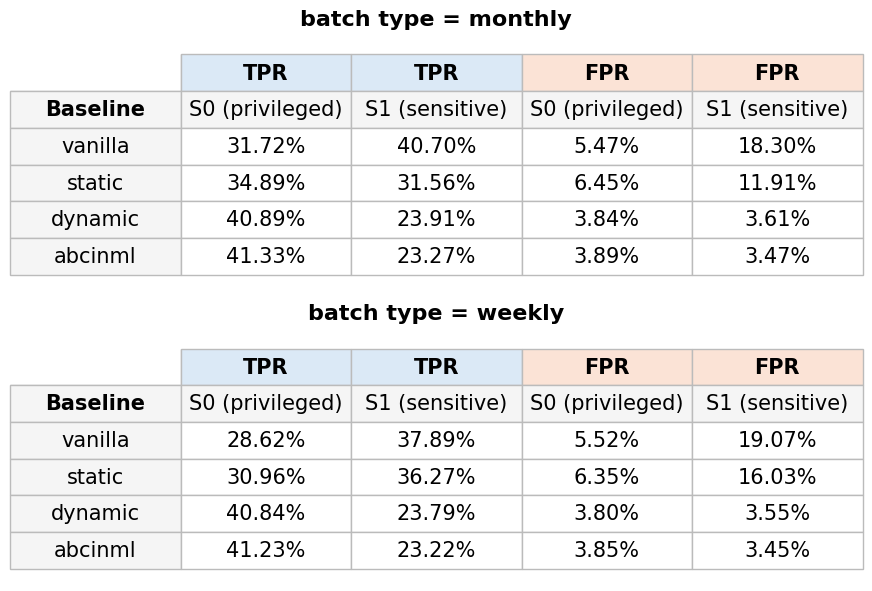

Metric               TPR                            FPR               
Group    S0 (privileged) S1 (sensitive) S0 (privileged) S1 (sensitive)
Baseline                                                              
vanilla            28.62          37.89            5.52          19.07
static             30.96          36.27            6.35          16.03
dynamic            40.84          23.79            3.80           3.55
abcinml            41.23          23.22            3.85           3.45

In [13]:
save_pivot_image('xgboost', results_dir / 'absolute_rates_pivot_xgboost.png')
plt.show()
absolute_rates_pivot('xgboost', 'weekly')

## Pivot table — mean metrics per alpha (ABCinML)

Table version of `alpha_analysis_global`: for each model, a pivot with `alpha` in the rows and the snapshot metrics in the columns, each cell being the **mean of the metric over all monthly batches** of `abcinml` for that alpha (same aggregation as the chart). Columns grouped into Performance (Accuracy, AUC-ROC) and Fairness (DP/TPR/FPR/Eq. Odds Diff.), values in %. Saved as images to `src/notebooks/figures/results_overview/`.

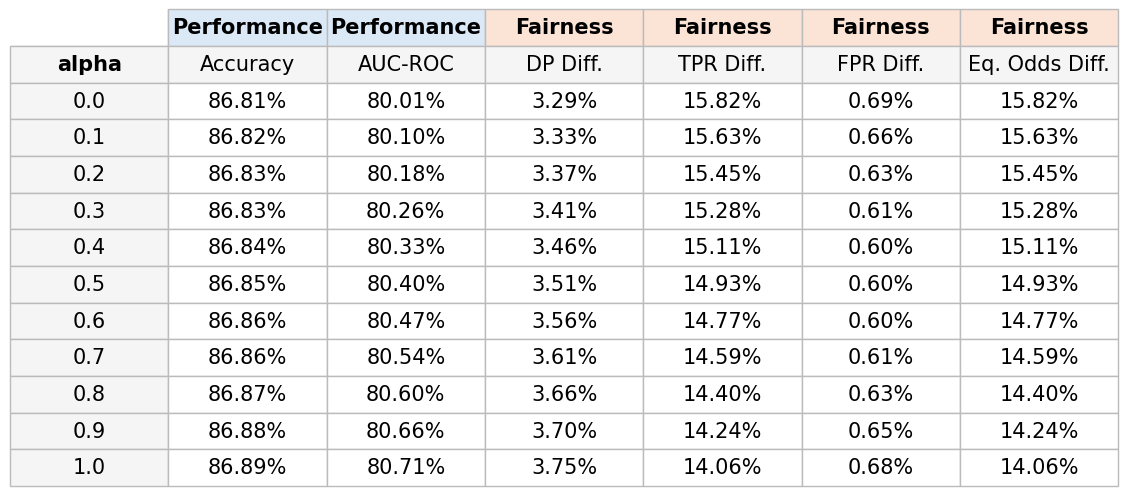

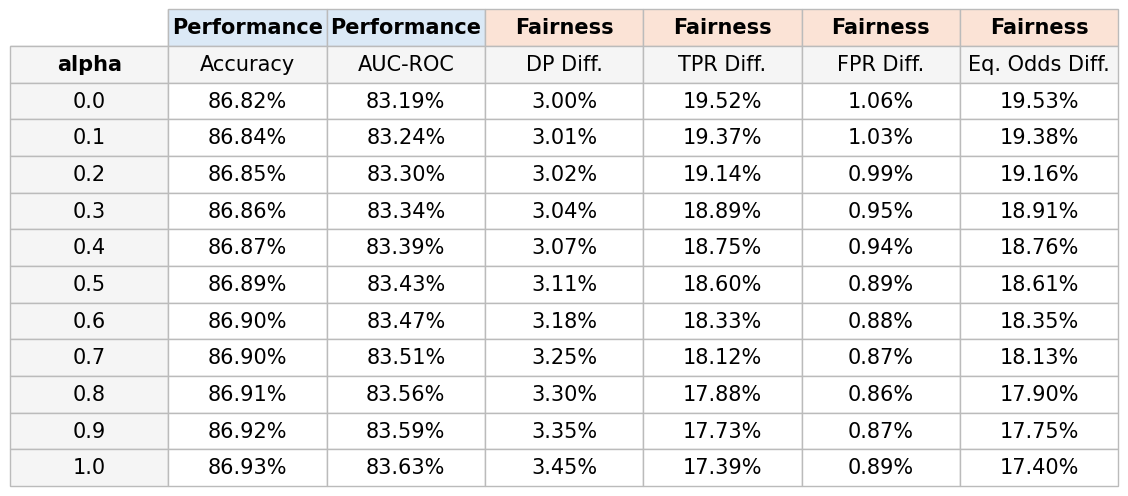

In [14]:
_ALPHA_COL_LABELS = {
    'acc': 'Accuracy',
    'auc': 'AUC-ROC',
    'dp': 'DP Diff.',
    'tpr_diff': 'TPR Diff.',
    'fpr_diff': 'FPR Diff.',
    'eq_odds_diff': 'Eq. Odds Diff.',
}
_PERF_METRICS = {'acc', 'auc'}  # the others are fairness metrics


def save_alpha_pivot_image(model_name, out_path):
    """Pivot alpha × metrics (mean over the monthly abcinml batches) as an image."""
    abc = monthly_df[
        (monthly_df['model_name'] == model_name) & (monthly_df['baseline'] == 'abcinml')
    ]
    piv = abc.groupby('alpha')[metric_cols].mean().sort_index()

    n_rows, n_cols = piv.shape
    fig, ax = plt.subplots(figsize=(1.9 * (n_cols + 1) + 1.0, 0.42 * (n_rows + 2) + 0.6))
    ax.axis('off')

    band = [''] + ['Performance' if c in _PERF_METRICS else 'Fairness' for c in metric_cols]
    header = ['alpha'] + [_ALPHA_COL_LABELS[c] for c in metric_cols]
    body = [
        [f'{a:.1f}'] + [f'{piv.loc[a, c] * 100:.2f}%' for c in metric_cols]
        for a in piv.index
    ]
    table_data = [band, header] + body

    tbl = ax.table(cellText=table_data, cellLoc='center', loc='center')
    tbl.auto_set_font_size(False)
    tbl.set_fontsize(15)
    tbl.scale(1, 2.2)

    perf_fill, fair_fill, light_gray = '#dbe9f6', '#fbe3d6', '#f5f5f5'
    for (r, c), cell in tbl.get_celld().items():
        cell.set_edgecolor('#bbbbbb')
        if r == 0:  # banda Performance/Fairness (bold, colorida)
            if c == 0:
                cell.set_facecolor('white')
                cell.visible_edges = 'BR'
            else:
                metric = metric_cols[c - 1]
                cell.set_facecolor(perf_fill if metric in _PERF_METRICS else fair_fill)
                cell.get_text().set_fontweight('bold')
        elif r == 1:  # header: only 'alpha' in bold; metrics normal, light gray
            cell.set_facecolor(light_gray)
            if c == 0:
                cell.get_text().set_fontweight('bold')
        elif c == 0:  # alpha column (values): light gray, no bold
            cell.set_facecolor(light_gray)

    fig.savefig(out_path, dpi=120, bbox_inches='tight', pad_inches=0.05)


save_alpha_pivot_image('logistic_regression', results_dir / 'alpha_analysis_pivot_lr.png')
plt.show()
save_alpha_pivot_image('xgboost', results_dir / 'alpha_analysis_pivot_xgboost.png')
plt.show()

## Forecast quality — MAE per epidemiological period

Recursively loads every `forecast_quality.csv` in `src/results/forecast_quality/`, concatenates them into a single DataFrame with columns derived from the path (`sensitive_attribute`, `batch_type`, `forecast_window`, `ema_alpha`) and assigns the epidemiological period to each row from `batch` (converted to a date according to `batch_type`, since the same `2019-04` label means a month for monthly and a week for weekly). It then aggregates the mean MAE ± std per `(forecaster, period)`, split by `sensitive_attribute`, and draws a heatmap saved to `src/results/forecast_quality/mae_by_period.png` (`RdYlGn_r` colormap: lower MAE = green, higher = red).

In [15]:
import re

# ── Load and concatenate all forecast_quality.csv files ─────────────────────
fq_root = ROOT / 'src' / 'results' / 'forecast_quality'
_folder_re = re.compile(
    r'(?P<batch_type>monthly|weekly)_forecast_window_(?P<forecast_window>\d+)_ema_alpha_(?P<ema_alpha>[\d.]+)'
)

frames = []
for csv_path in sorted(fq_root.rglob('forecast_quality.csv')):
    m = _folder_re.match(csv_path.parent.name)
    if m is None:
        continue
    d = pd.read_csv(csv_path)
    d['sensitive_attribute'] = csv_path.parent.parent.name
    d['batch_type'] = m.group('batch_type')
    d['forecast_window'] = int(m.group('forecast_window'))
    d['ema_alpha'] = float(m.group('ema_alpha'))
    frames.append(d)

fq_df = pd.concat(frames, ignore_index=True)

# ── Epidemiological period per row ──────────────────────────────────────────
# batch -> date according to batch_type (the label is ambiguous between month and week)
PERIOD_ORDER_EN = ['pre-pandemic', 'acute pandemic 1', 'acute pandemic 2', 'transition', 'endemic']
_PERIOD_BINS = [
    pd.Timestamp('2000-01-01'),
    pd.Timestamp('2020-03-01'),   # pre-pandemic   < 2020-03
    pd.Timestamp('2022-01-01'),   # acute pandemic 1
    pd.Timestamp('2023-01-01'),   # acute pandemic 2
    pd.Timestamp('2024-01-01'),   # transition
    pd.Timestamp('2100-01-01'),   # endemic        >= 2024-01
]

_dt_map = {}
for bt in fq_df['batch_type'].unique():
    labels = fq_df.loc[fq_df['batch_type'] == bt, 'batch'].astype(str).unique().tolist()
    for lab, dt in zip(labels, metrics_utils._batch_to_datetime(labels, bt)):
        _dt_map[(lab, bt)] = dt

fq_df['batch_dt'] = pd.to_datetime(
    [_dt_map[(str(b), bt)] for b, bt in zip(fq_df['batch'], fq_df['batch_type'])]
)
fq_df['period'] = pd.cut(
    fq_df['batch_dt'], bins=_PERIOD_BINS, labels=PERIOD_ORDER_EN, right=False, ordered=True
)

print(f'{len(fq_df):,} rows concatenated from {len(frames)} files')
print('sensitive_attribute:', sorted(fq_df['sensitive_attribute'].unique()))
print('batch_type:', sorted(fq_df['batch_type'].unique()),
      '| forecast_window:', sorted(fq_df['forecast_window'].unique()))
fq_df.head()

14,376 rows concatenated from 8 files
sensitive_attribute: ['IDADE_BIN']
batch_type: ['monthly', 'weekly'] | forecast_window: [np.int64(3), np.int64(5), np.int64(10)]


,batch,forecaster,proportion,forecast_value,real_value,abs_error,bias,sensitive_attribute,batch_type,forecast_window,ema_alpha,batch_dt,period
0,2019-11,sma,S0_Y0,0.773734,0.802693,0.028959,-0.028959,IDADE_BIN,monthly,10,0.3,2019-11-01,pre-pandemic
1,2019-11,sma,S0_Y1,0.077983,0.076112,0.001871,0.001871,IDADE_BIN,monthly,10,0.3,2019-11-01,pre-pandemic
2,2019-11,sma,S1_Y0,0.105097,0.080796,0.024301,0.024301,IDADE_BIN,monthly,10,0.3,2019-11-01,pre-pandemic
3,2019-11,sma,S1_Y1,0.043186,0.040398,0.002788,0.002788,IDADE_BIN,monthly,10,0.3,2019-11-01,pre-pandemic
4,2019-11,ema,S0_Y0,0.769401,0.802693,0.033292,-0.033292,IDADE_BIN,monthly,10,0.3,2019-11-01,pre-pandemic


In [16]:
# ── Mean MAE ± std per (forecaster, period), split by sensitive_attribute ──
mae_agg = (
    fq_df.groupby(['sensitive_attribute', 'forecaster', 'period'], observed=True)['abs_error']
    .agg(mae_mean='mean', mae_std='std')
    .reset_index()
)

_FORECASTER_ORDER = ['sma', 'ema']

for sens in sorted(mae_agg['sensitive_attribute'].unique()):
    g = mae_agg[mae_agg['sensitive_attribute'] == sens].copy()
    g['MAE (mean ± std)'] = g.apply(
        lambda r: f"{r['mae_mean']:.4f} ± {r['mae_std']:.4f}", axis=1
    )
    table = (
        g.pivot(index='forecaster', columns='period', values='MAE (mean ± std)')
        .reindex(index=_FORECASTER_ORDER, columns=PERIOD_ORDER_EN)
    )
    table.index.name = f'sensitive_attribute = {sens}'
    print(f'\nMean MAE ± std — sensitive_attribute = {sens}')
    display(table)


Mean MAE ± std — sensitive_attribute = IDADE_BIN


period,pre-pandemic,acute pandemic 1,acute pandemic 2,transition,endemic
sensitive_attribute = IDADE_BIN,,,,,
sma,0.0210 ± 0.0203,0.0314 ± 0.0363,0.0417 ± 0.0418,0.0258 ± 0.0335,0.0201 ± 0.0264
ema,0.0178 ± 0.0163,0.0223 ± 0.0264,0.0338 ± 0.0338,0.0188 ± 0.0259,0.0150 ± 0.0199


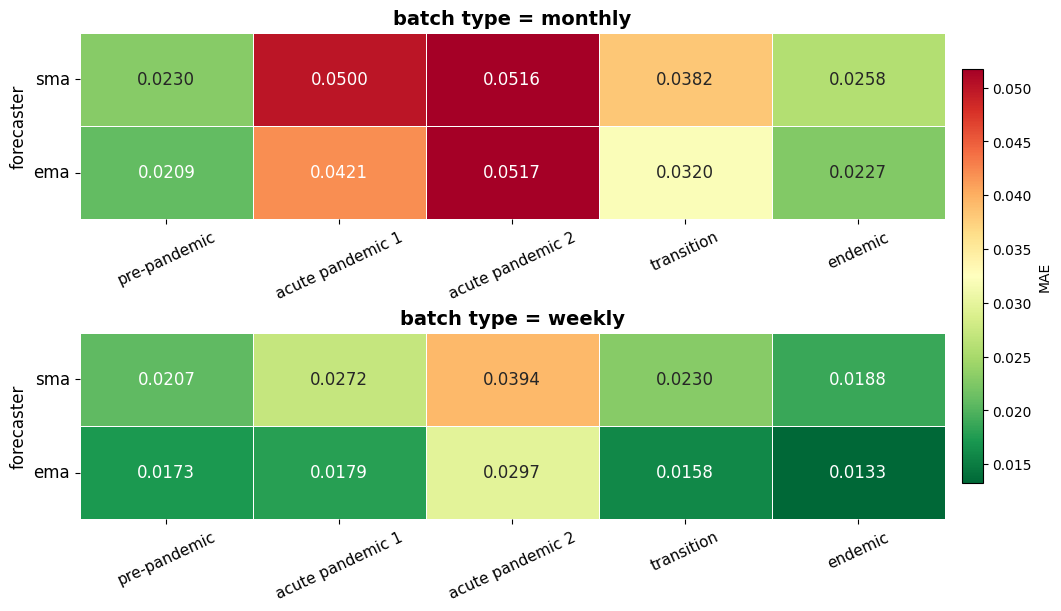

In [17]:
import seaborn as sns
import matplotlib as mpl

# ── Heatmap: mean MAE, forecaster × period — split by batch_type ────────────
# (one subplot per batch_type × sensitive_attribute; shared color scale)
mae_agg_bt = (
    fq_df.groupby(['sensitive_attribute', 'batch_type', 'forecaster', 'period'], observed=True)['abs_error']
    .agg(mae_mean='mean', mae_std='std')
    .reset_index()
)

_BATCH_TYPE_ORDER = ['monthly', 'weekly']
attrs = sorted(fq_df['sensitive_attribute'].unique())
batch_types = [bt for bt in _BATCH_TYPE_ORDER if bt in fq_df['batch_type'].unique()]

vmin = float(mae_agg_bt['mae_mean'].min())
vmax = float(mae_agg_bt['mae_mean'].max())

nrows, ncols = len(batch_types), len(attrs)
fig, axes = plt.subplots(
    nrows, ncols,
    figsize=(1.7 * len(PERIOD_ORDER_EN) * ncols + 2, 3.0 * nrows),
    squeeze=False,
    layout='constrained',
)

for r, bt in enumerate(batch_types):
    for c, sens in enumerate(attrs):
        ax = axes[r][c]
        sub = mae_agg_bt[
            (mae_agg_bt['batch_type'] == bt) & (mae_agg_bt['sensitive_attribute'] == sens)
        ]
        mat = (
            sub.pivot(index='forecaster', columns='period', values='mae_mean')
            .reindex(index=_FORECASTER_ORDER, columns=PERIOD_ORDER_EN)
        )
        sns.heatmap(
            mat, annot=True, fmt='.4f', cmap='RdYlGn_r', ax=ax,
            vmin=vmin, vmax=vmax, cbar=False,
            linewidths=0.5, linecolor='white', annot_kws={'fontsize': 12},
        )
        title = f'batch type = {bt}' if ncols == 1 else f'{sens} — batch type = {bt}'
        ax.set_title(title, fontsize=14, fontweight='bold')
        ax.set_xlabel('')
        ax.set_ylabel('forecaster', fontsize=12)
        ax.tick_params(axis='x', rotation=25, labelsize=11)
        ax.tick_params(axis='y', rotation=0, labelsize=12)

# Single colorbar shared by all panels
sm = mpl.cm.ScalarMappable(cmap='RdYlGn_r', norm=mpl.colors.Normalize(vmin=vmin, vmax=vmax))
fig.colorbar(sm, ax=axes, label='MAE', shrink=0.85, pad=0.02)

out_path = fq_root / 'mae_by_period.png'
fig.savefig(out_path, dpi=120, bbox_inches='tight')

plt.show()

## Forecast vs. real value over the batches

Compares the forecasted values (SMA and EMA) with the observed real value, batch by batch, for the `IDADE_BIN` attribute. Since the four proportions of the joint distribution (S0_Y0, S0_Y1, S1_Y0, S1_Y1) sum to 1 in each batch — their mean would be constant (0.25) —, each proportion is shown **separately**: 4×2 grid (proportion × `batch_type`). `forecast_value` is the mean over the windows (`forecast_window` 3/5/10); `real_value` is the same for any forecaster. Background shaded by the epidemiological periods of the project. Saved to `src/results/forecast_quality/forecast_vs_real.png`.

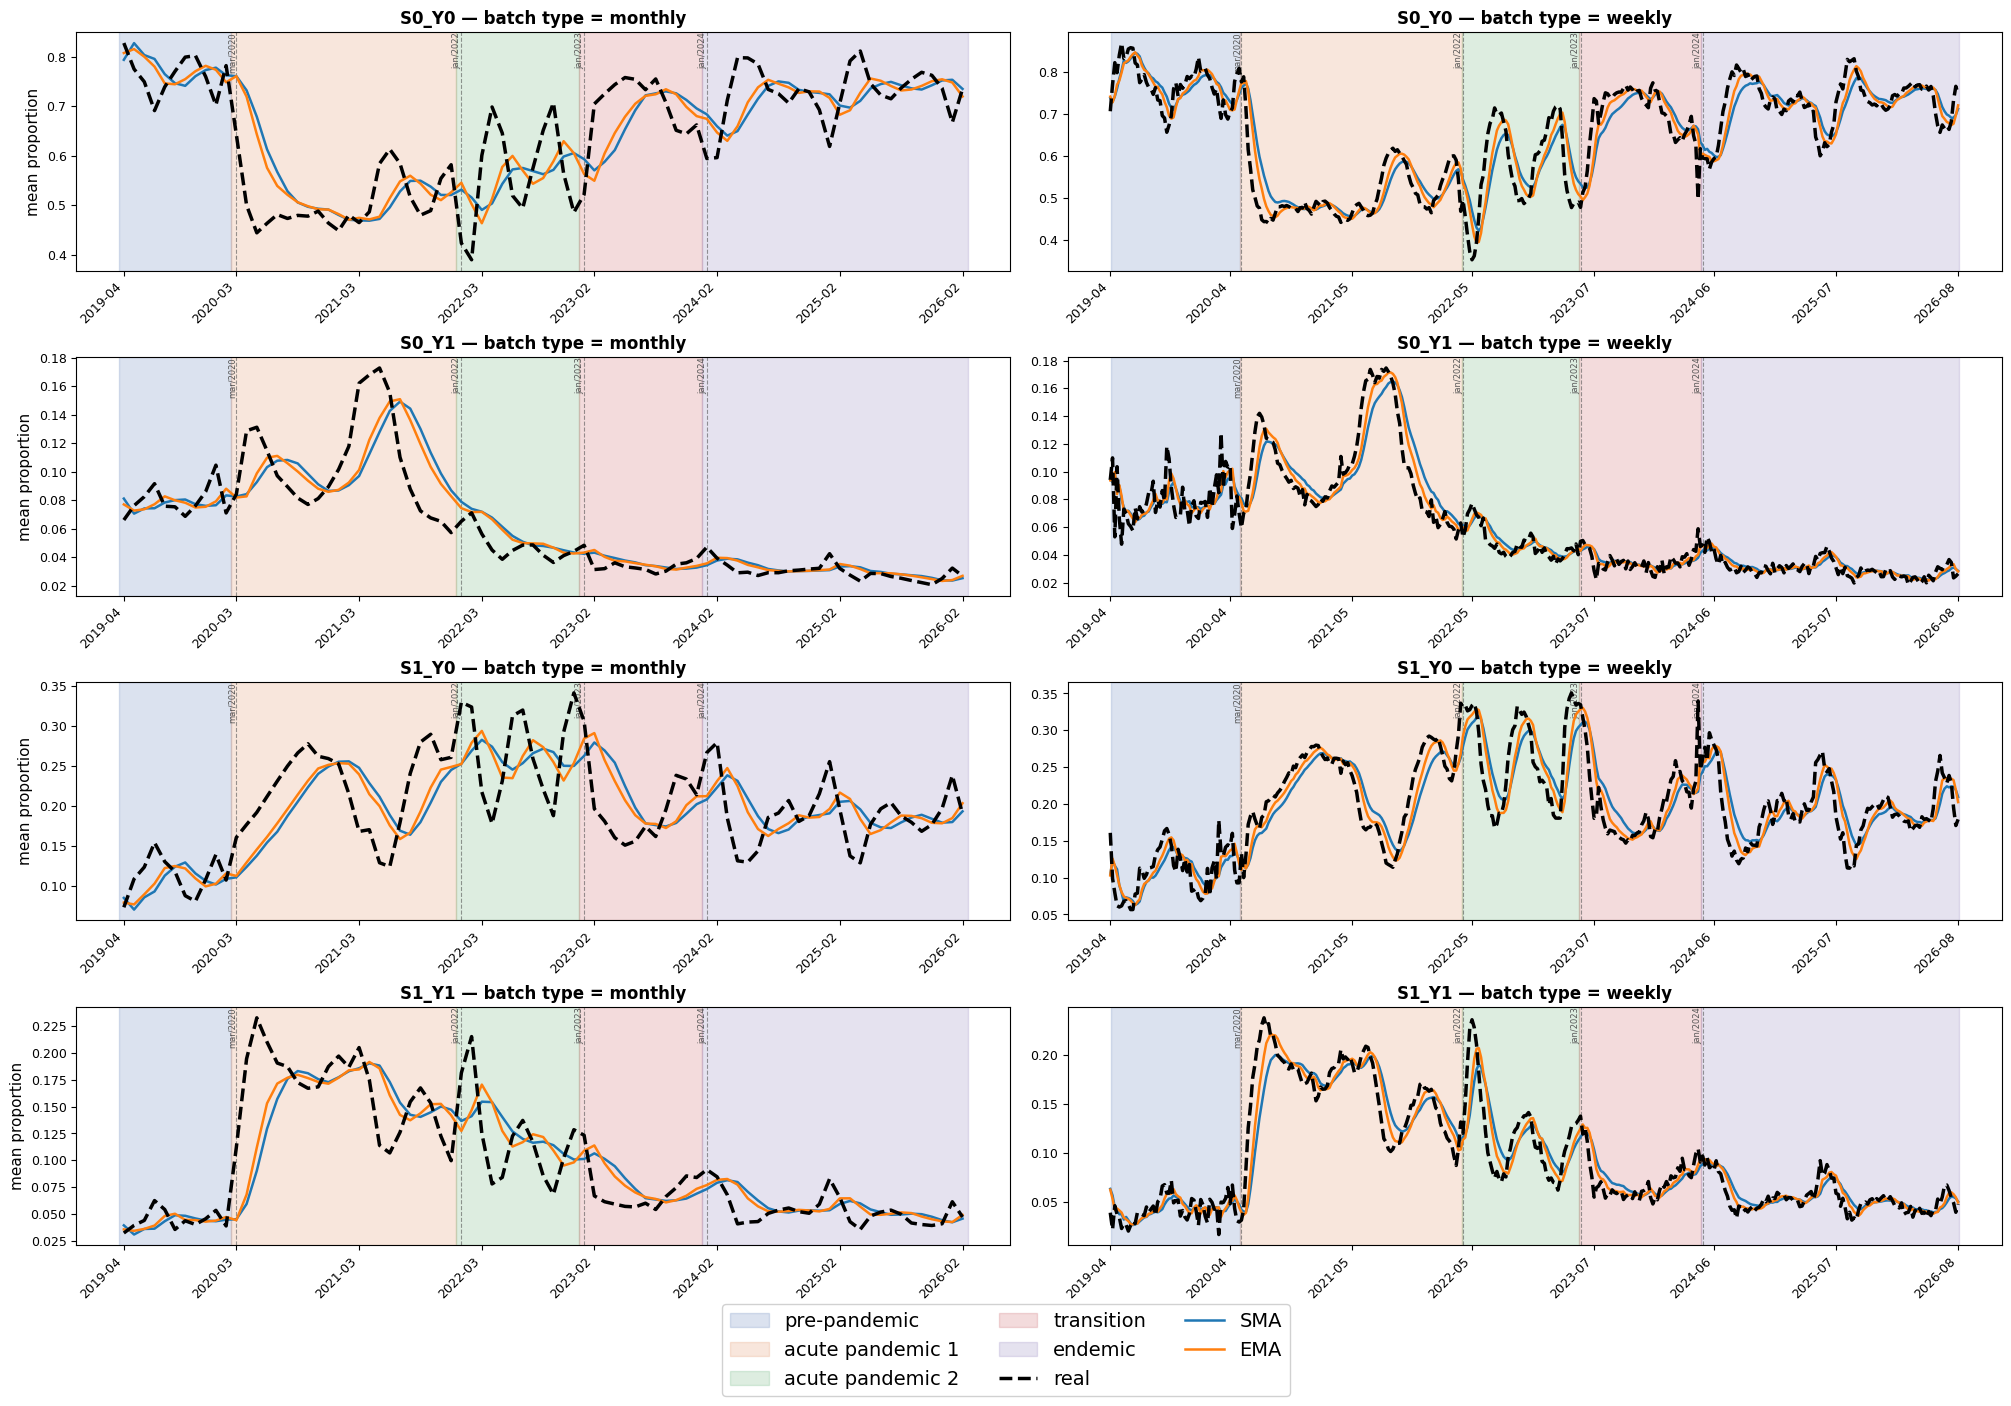

In [18]:
# ── Forecast (SMA/EMA) vs real per proportion and batch_type ─────────────────
fq_age = fq_df[fq_df['sensitive_attribute'] == 'IDADE_BIN'].copy()

_PROPORTIONS = ['S0_Y0', 'S0_Y1', 'S1_Y0', 'S1_Y1']
_BT_ORDER = [bt for bt in ['monthly', 'weekly'] if bt in fq_age['batch_type'].unique()]
_FORECASTER_STYLE = {'sma': '#1f77b4', 'ema': '#ff7f0e'}

# forecast: mean over the windows (keeps proportion/forecaster separate)
fc = fq_age.groupby(
    ['batch_type', 'proportion', 'forecaster', 'batch'], as_index=False
)['forecast_value'].mean()
# real: identical across forecasters/windows
rv = fq_age.groupby(
    ['batch_type', 'proportion', 'batch'], as_index=False
)['real_value'].mean()

fig, axes = plt.subplots(len(_PROPORTIONS), len(_BT_ORDER), figsize=(20, 14),
                         squeeze=False, layout='constrained')

for r, prop in enumerate(_PROPORTIONS):
    for c, bt in enumerate(_BT_ORDER):
        ax = axes[r][c]

        all_batch_labels = sorted(fq_age[fq_age['batch_type'] == bt]['batch'].astype(str).unique())
        xpos = {b: i for i, b in enumerate(all_batch_labels)}

        _add_period_spans(ax, all_batch_labels, bt)

        # real value (black dashed, thicker)
        rsub = rv[(rv['batch_type'] == bt) & (rv['proportion'] == prop)].copy()
        rsub['x'] = rsub['batch'].astype(str).map(xpos)
        rsub = rsub.sort_values('x')
        ax.plot(rsub['x'], rsub['real_value'], color='black', linestyle='--',
                linewidth=2.5, label='real', zorder=4)

        # SMA and EMA forecasts (solid)
        for fk in ['sma', 'ema']:
            fsub = fc[(fc['batch_type'] == bt) & (fc['proportion'] == prop) & (fc['forecaster'] == fk)].copy()
            fsub['x'] = fsub['batch'].astype(str).map(xpos)
            fsub = fsub.sort_values('x')
            ax.plot(fsub['x'], fsub['forecast_value'], color=_FORECASTER_STYLE[fk],
                    linewidth=1.8, label=fk.upper(), zorder=3)

        ax.set_title(f'{prop} — batch type = {bt}', fontsize=12, fontweight='bold')
        if c == 0:
            ax.set_ylabel('mean proportion', fontsize=11)
        _apply_bin_xticks(ax, all_batch_labels, n_bins=8)
        ax.tick_params(axis='x', labelsize=9)
        ax.tick_params(axis='y', labelsize=9)

# Softer period shading (project visual identity)
for ax in fig.axes:
    for patch in ax.patches:
        patch.set_alpha(0.20)

# Single legend with the three series
series_handles, series_labels = axes[0][0].get_legend_handles_labels()
fig.legend(series_handles, series_labels, loc='outside lower center',
           ncol=3, fontsize=14, framealpha=0.9)

out_path = fq_root / 'forecast_vs_real.png'
fig.savefig(out_path, dpi=150, bbox_inches='tight')

plt.show()

## Impact of EMA on the downstream fairness metrics of ABCInML

Compares, within the `abcinml` baseline, the **SMA** vs **EMA** forecaster on the downstream metrics (Accuracy, AUC and the DP/TPR/FPR fairness diffs). For a controlled comparison on the **same horizon**, both techniques are restricted to `forecast_window == 5` (EMA only exists for that window). In each `(model_name, batch_type)`, the metrics are aggregated by the mean per batch (over the alphas).

1. **Time curves** — grid with `model × batch_type` rows and one column per metric; SMA (solid blue) and EMA (dashed orange), window-5 moving average, with period shading. Saved to `src/results/forecast_quality/ema_vs_sma_downstream.png`.
2. **Comparison tables** (image) — three tables (global mean, MB = max |bias|, TS = temporal stability) with `(model, batch_type, technique)` rows and sp/tpr/fpr columns; the cell with the lowest value per column within each `(model, batch_type)` is highlighted in green. Saved to `src/results/forecast_quality/ema_vs_sma_tables.png`.

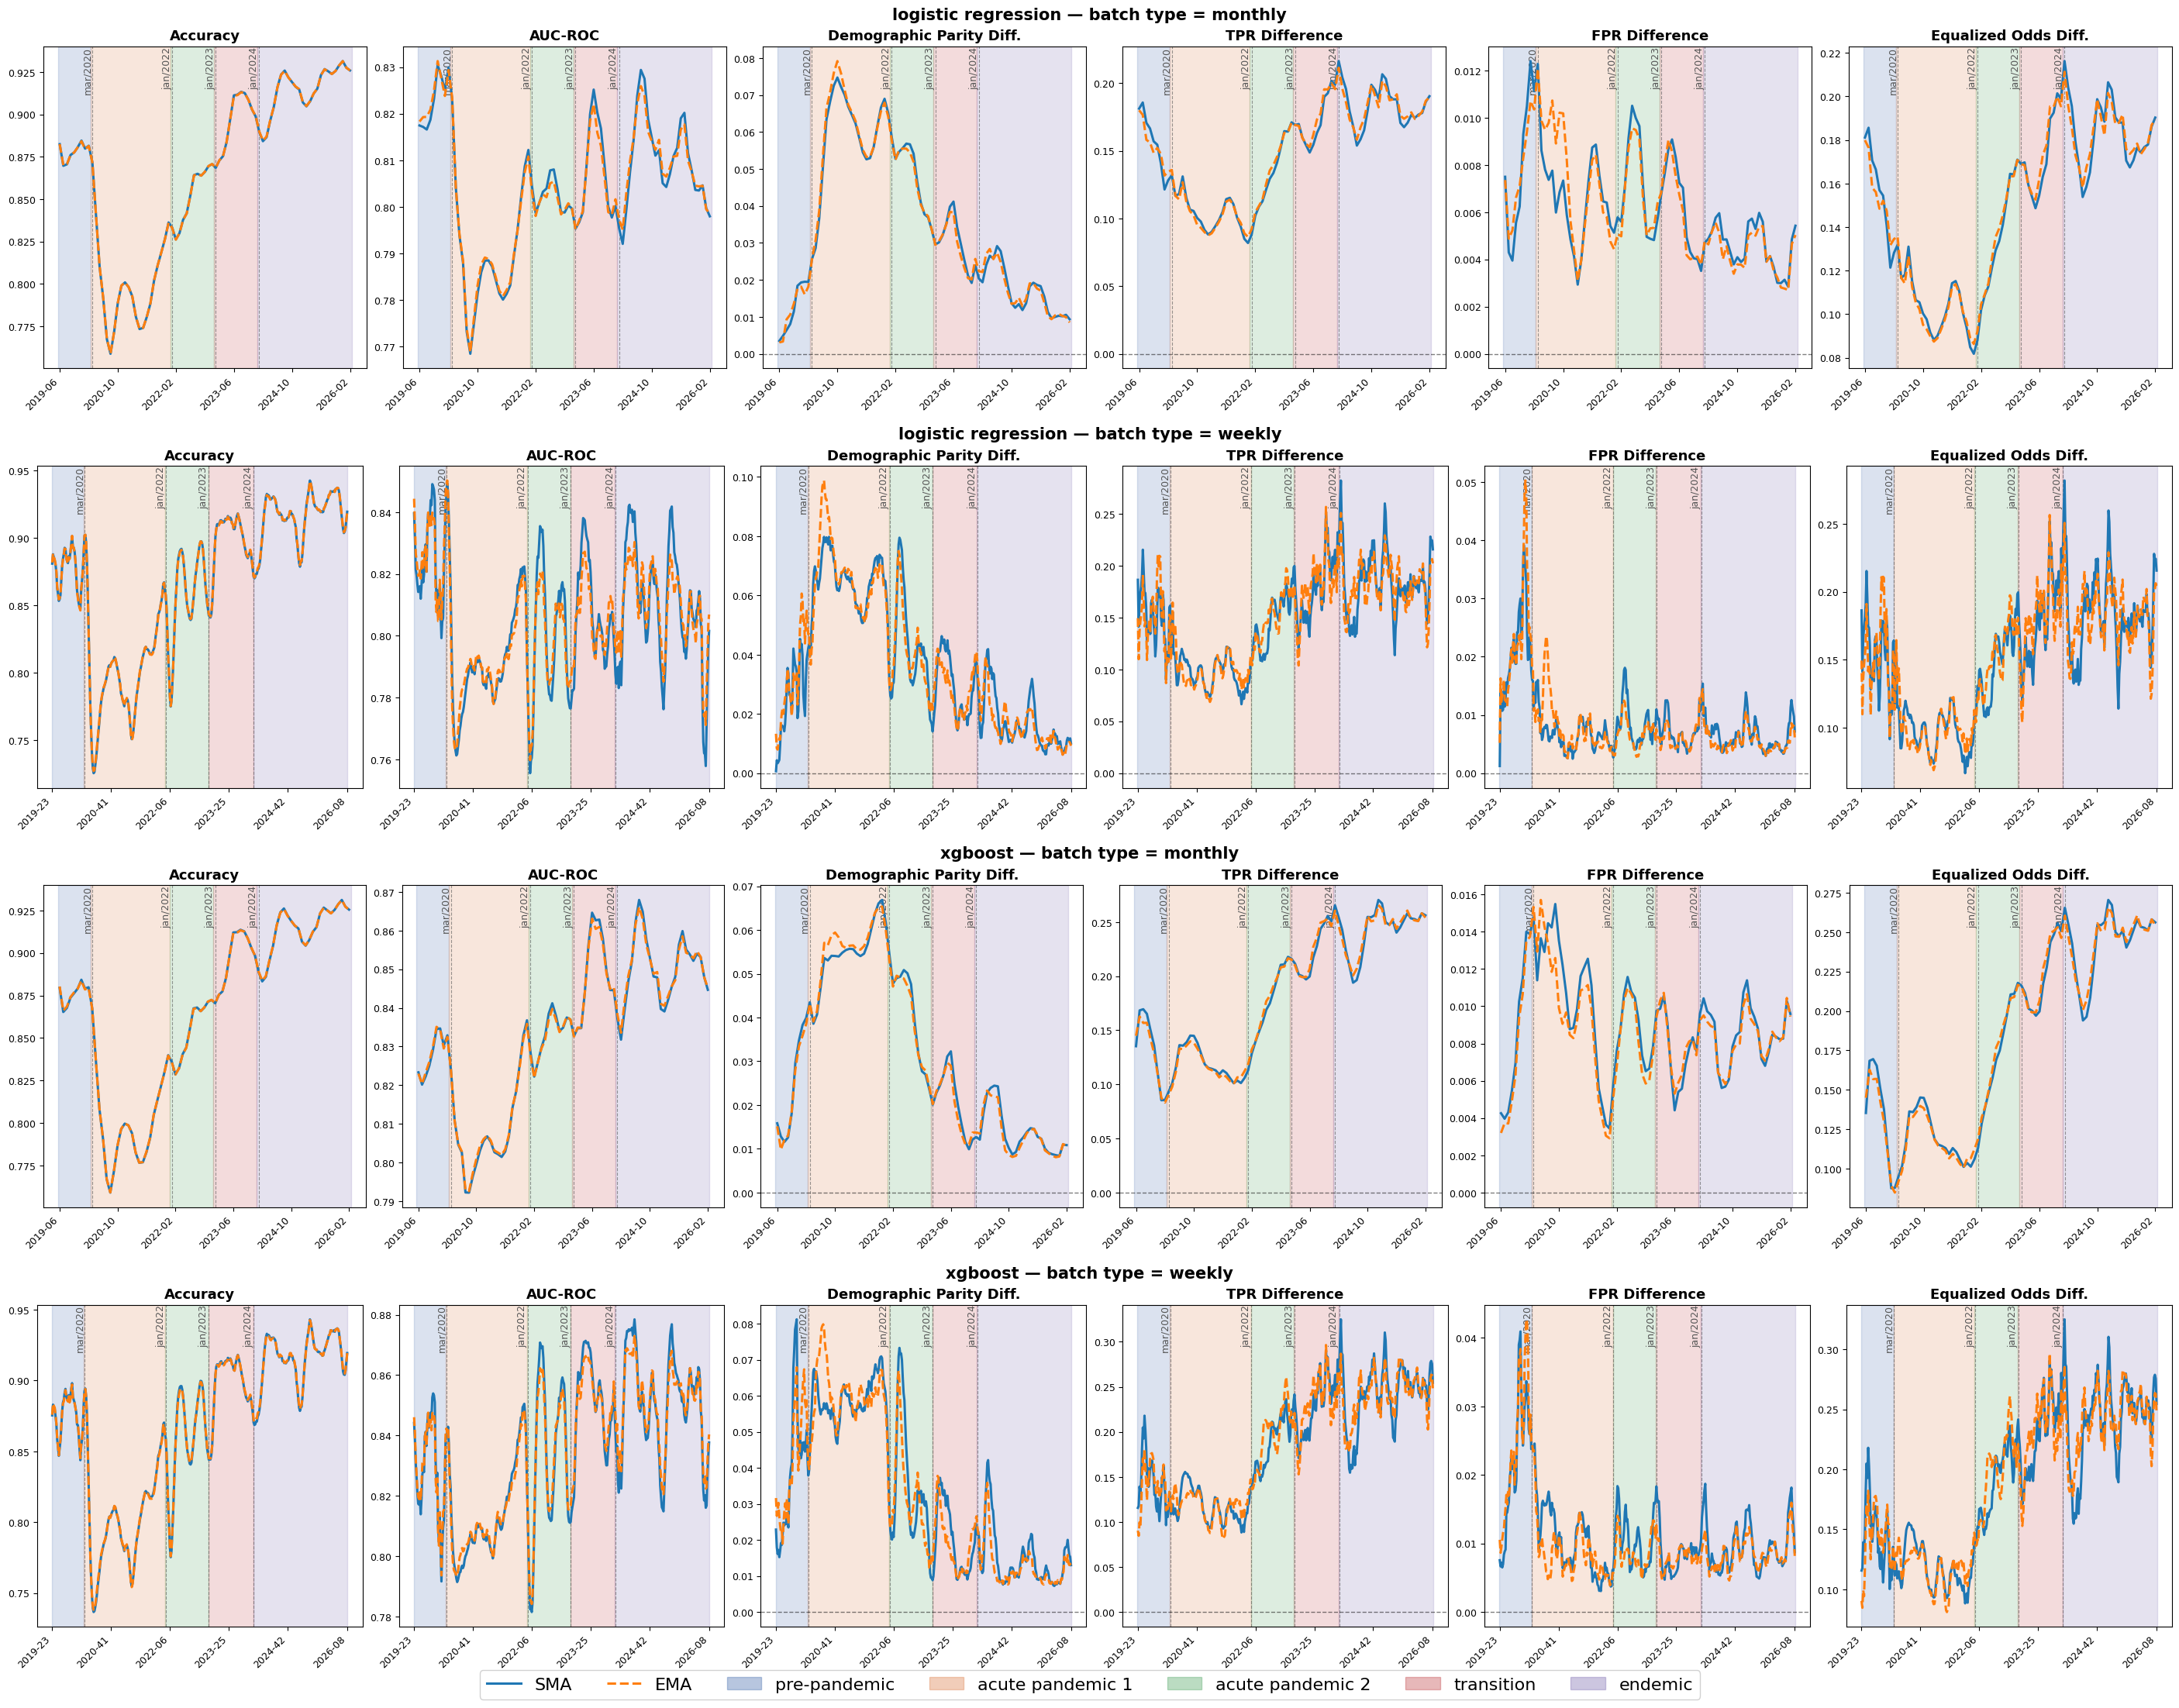

In [19]:
# 1. Load abcinml + 2. period per row ─────────────────────────────────────
abc_all = pd.read_csv(ROOT / 'src' / 'results' / 'all' / 'assessment_all_baselines.csv')
abc_all = abc_all[abc_all['baseline'] == 'abcinml'].copy()
# Same filter as the previous cells: Kamiran & Calders only (see the comment in cell 2)
abc_all = abc_all[abc_all['fairness_correction'] == 'kamiran_rw'].copy()

_dt_map_abc = {}
for _bt in abc_all['batch_type'].unique():
    _labels = abc_all.loc[abc_all['batch_type'] == _bt, 'batch'].astype(str).unique().tolist()
    for _lab, _dt in zip(_labels, metrics_utils._batch_to_datetime(_labels, _bt)):
        _dt_map_abc[(_lab, _bt)] = _dt
abc_all['batch_dt'] = pd.to_datetime(
    [_dt_map_abc[(str(b), bt)] for b, bt in zip(abc_all['batch'], abc_all['batch_type'])]
)
abc_all['period'] = pd.cut(
    abc_all['batch_dt'], bins=_PERIOD_BINS, labels=PERIOD_ORDER_EN, right=False, ordered=True
)

# Controlled SMA vs EMA comparison on the same horizon (forecast_window == 5)
abc = abc_all[
    abc_all['forecasting_technique'].isin(['sma', 'ema']) & (abc_all['forecast_window'] == 5)
].copy()

_TECH_STYLE = {'sma': ('#1f77b4', '-'), 'ema': ('#ff7f0e', '--')}
_COMBOS = [(m, bt) for m in ['logistic_regression', 'xgboost'] for bt in ['monthly', 'weekly']]

# 3. Curvas temporais SMA vs EMA ────────────────────────────────────────────
fig = plt.figure(figsize=(28, 22), layout='constrained')
subfigs = fig.subfigures(len(_COMBOS), 1)

line_handles, period_handles = {}, []
for subfig, (model, bt) in zip(subfigs, _COMBOS):
    subfig.suptitle(f'{MODEL_LABELS[model]} — batch type = {bt}', fontsize=15, fontweight='bold')
    axes = subfig.subplots(1, len(_SNAPSHOT_METRICS))

    sub_mb = abc[(abc['model_name'] == model) & (abc['batch_type'] == bt)]
    all_batch_labels = sorted(sub_mb['batch'].astype(str).unique())

    for col_idx, (col, label) in enumerate(_SNAPSHOT_METRICS):
        ax = axes[col_idx]
        ph = _add_period_spans(ax, all_batch_labels, bt)
        if not period_handles:
            period_handles = ph
        if col in ('dp', 'tpr_diff', 'fpr_diff'):
            ax.axhline(y=0, color='black', linestyle='--', linewidth=1.0, alpha=0.5, zorder=2)

        for tech, (color, ls) in _TECH_STYLE.items():
            s = sub_mb[sub_mb['forecasting_technique'] == tech]
            per_batch = s.groupby('batch')[col].mean()
            per_batch = per_batch.reindex([b for b in all_batch_labels if b in per_batch.index])
            ma = per_batch.rolling(window=5, min_periods=1).mean()
            x = [all_batch_labels.index(b) for b in ma.index]
            line, = ax.plot(x, ma.values, color=color, linestyle=ls, linewidth=2.2,
                            label=tech.upper(), zorder=3)
            line_handles[tech] = line

        ax.set_title(label, fontsize=13, fontweight='bold')
        _apply_bin_xticks(ax, all_batch_labels, n_bins=6)
        ax.tick_params(axis='x', labelsize=9)
        ax.tick_params(axis='y', labelsize=9)

# Softer period shading (project visual identity)
for ax in fig.axes:
    for patch in ax.patches:
        patch.set_alpha(0.20)
    for text in ax.texts:
        text.set_fontsize(9)

all_handles = [line_handles['sma'], line_handles['ema']] + period_handles
all_labels = ['SMA', 'EMA'] + [h.get_label() for h in period_handles]
leg = fig.legend(all_handles, all_labels, loc='outside lower center',
                 ncol=len(all_handles), fontsize=16, framealpha=0.9)
for lp in leg.get_patches():
    lp.set_alpha(0.4)

out_path = fq_root / 'ema_vs_sma_downstream.png'
fig.savefig(out_path, dpi=150, bbox_inches='tight')

plt.show()

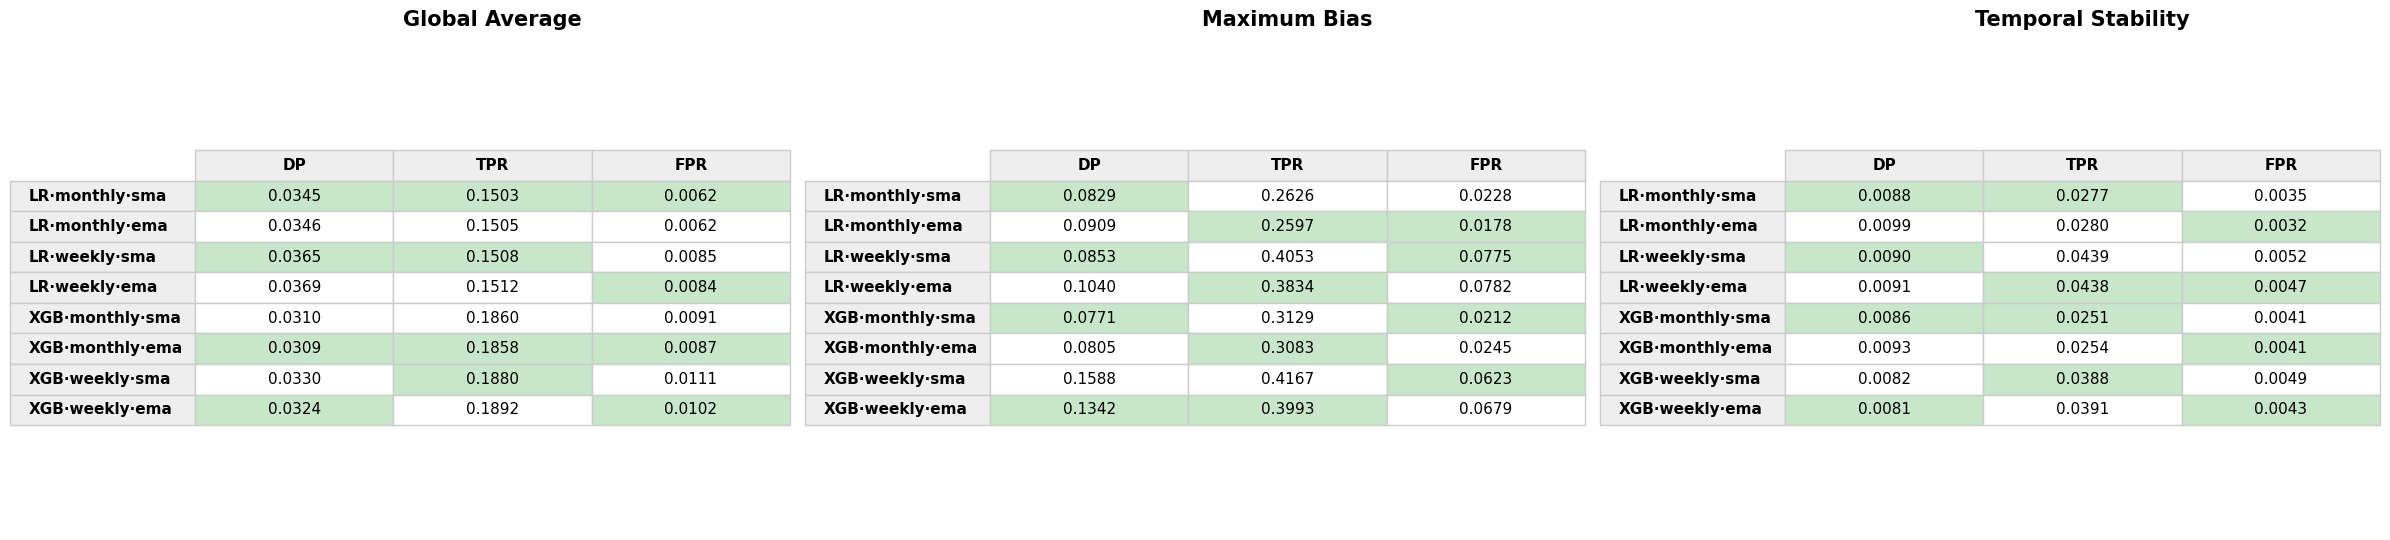

In [20]:
# 4. Comparison tables (image): global mean, MB and TS ───────────────────────
_METRICS3 = ['dp', 'tpr_diff', 'fpr_diff']
_METRICS3_LABELS = ['DP', 'TPR', 'FPR']  # short labels for the table header
_MODEL_ABBR = {'logistic_regression': 'LR', 'xgboost': 'XGB'}
_COMBO_ROWS = [(m, bt, t) for m in ['logistic_regression', 'xgboost']
               for bt in ['monthly', 'weekly'] for t in ['sma', 'ema']]


def _metric_series(model, bt, tech, metric):
    """Time series of the metric (mean per batch over alphas), sorted chronologically."""
    s = abc[(abc['model_name'] == model) & (abc['batch_type'] == bt)
            & (abc['forecasting_technique'] == tech)]
    per_batch = s.groupby('batch')[metric].mean()
    return per_batch.reindex(sorted(per_batch.index))


def _build_stat_df(kind):
    data = {}
    for metric in _METRICS3:
        col = []
        for (m, bt, t) in _COMBO_ROWS:
            s = _metric_series(m, bt, t, metric)
            if kind == 'mean':
                v = s.mean()
            elif kind == 'MB':
                v = s.abs().max()
            elif kind == 'TS':
                v = s.diff().abs().mean()
            col.append(v)
        data[metric] = col
    idx = pd.MultiIndex.from_tuples(
        [(_MODEL_ABBR[m], bt, t) for (m, bt, t) in _COMBO_ROWS],
        names=['model', 'batch_type', 'tech'],
    )
    return pd.DataFrame(data, index=idx)


_STAT_DFS = {
    'Global Average': _build_stat_df('mean'),
    'Maximum Bias': _build_stat_df('MB'),
    'Temporal Stability': _build_stat_df('TS'),
}


def _render_stat_table(ax, df, title):
    ax.axis('off')
    ax.set_title(title, fontsize=15, fontweight='bold', pad=14)

    rows = list(df.index)
    row_labels = [f'{m}·{bt}·{t}' for (m, bt, t) in rows]
    cell_text = [[f'{df.iloc[i][c]:.4f}' for c in _METRICS3] for i in range(len(rows))]

    # lowest value per column within each (model, batch_type) -> green
    groups = {}
    for i, (m, bt, t) in enumerate(rows):
        groups.setdefault((m, bt), []).append(i)
    highlight = [[False] * len(_METRICS3) for _ in rows]
    for ci, c in enumerate(_METRICS3):
        for idxs in groups.values():
            best = min(idxs, key=lambda k: df.iloc[k][c])
            highlight[best][ci] = True

    tbl = ax.table(cellText=cell_text, rowLabels=row_labels, colLabels=_METRICS3_LABELS,
                   cellLoc='center', loc='center')
    tbl.auto_set_font_size(False)
    tbl.set_fontsize(11)
    tbl.scale(1, 1.6)

    for (r, c), cell in tbl.get_celld().items():
        cell.set_edgecolor('#cccccc')
        if r == 0 or c == -1:  # column header / row labels
            cell.set_facecolor('#eeeeee')
            cell.get_text().set_fontweight('bold')
        elif highlight[r - 1][c]:  # lowest value of the technique in the group
            cell.set_facecolor('#c8e6c9')


fig, axes = plt.subplots(1, 3, figsize=(24, 5.5))
for ax, (title, df) in zip(axes, _STAT_DFS.items()):
    _render_stat_table(ax, df, title)

fig.tight_layout()
out_path = fq_root / 'ema_vs_sma_tables.png'
fig.savefig(out_path, dpi=150, bbox_inches='tight')

plt.show()

## Triple comparison SMA vs EMA vs Oracle — bottleneck diagnosis

Extends the previous comparison by adding the **Oracle** (theoretical ceiling: uses the real distribution of the next batch). Diagnosis: if the Oracle greatly reduces the bias (DP) relative to SMA, **forecasting is the bottleneck** of ABCInML (SCENARIO A); if the Oracle does not improve much, the bottleneck is the **reweighing** (SCENARIO B). The three techniques are restricted to `forecast_window == 5` (same horizon). Outputs in `src/results/forecast_quality/`.

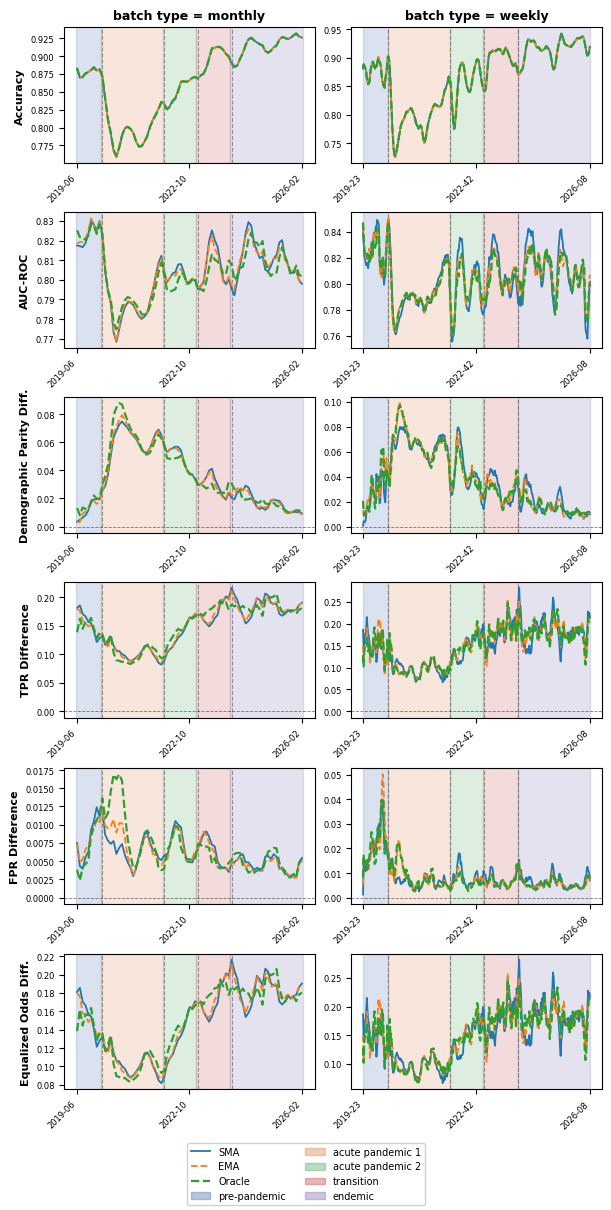

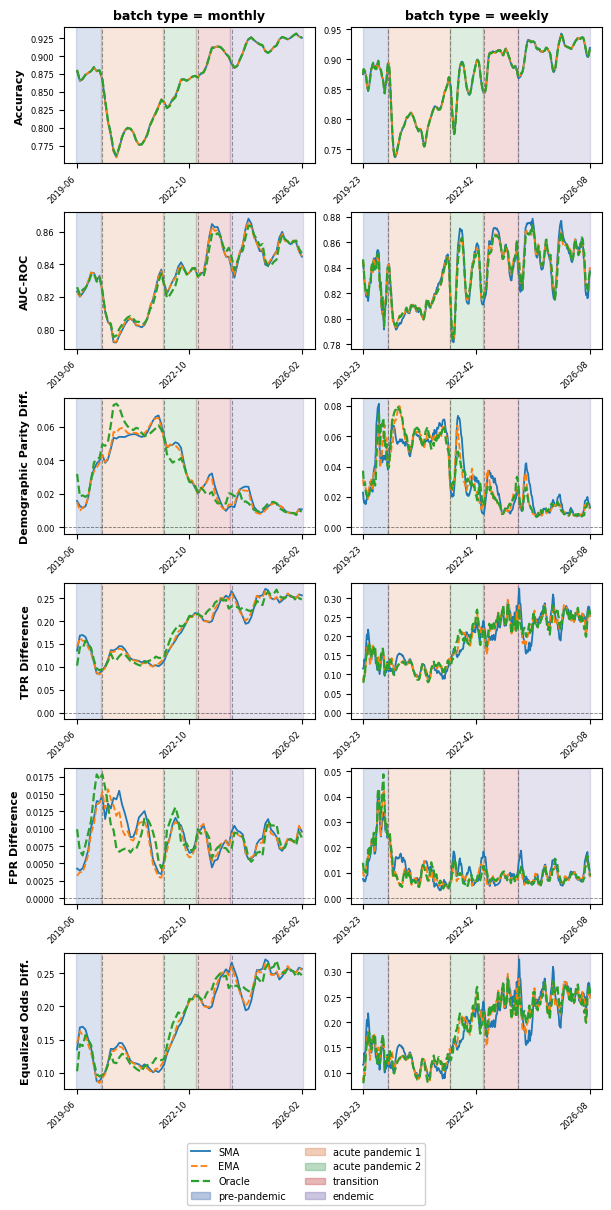

In [21]:
# Triple comparison: restrict the 3 techniques to the same horizon (window == 5)
abc3 = abc_all[
    abc_all['forecasting_technique'].isin(['sma', 'ema', 'oracle']) & (abc_all['forecast_window'] == 5)
].copy()

_TECH_STYLE3 = {
    'sma': ('#1f77b4', '-', 1.3),
    'ema': ('#ff7f0e', '--', 1.3),
    'oracle': ('#2ca02c', '--', 1.6),   # thicker dashed green = theoretical ceiling
}
_TECH_LABEL3 = {'sma': 'SMA', 'ema': 'EMA', 'oracle': 'Oracle'}
_BT_COLS = ['monthly', 'weekly']


def _plot_triple_metric(ax, model, bt, col, is_fairness):
    all_batch_labels = sorted(
        abc3[(abc3['model_name'] == model) & (abc3['batch_type'] == bt)]['batch'].astype(str).unique()
    )
    ph = _add_period_spans(ax, all_batch_labels, bt)
    if is_fairness:
        ax.axhline(y=0, color='black', linestyle='--', linewidth=0.6, alpha=0.5, zorder=2)
    line_handles = {}
    for tech, (color, ls, lw) in _TECH_STYLE3.items():
        s = abc3[(abc3['model_name'] == model) & (abc3['batch_type'] == bt)
                 & (abc3['forecasting_technique'] == tech)]
        per_batch = s.groupby('batch')[col].mean()
        per_batch = per_batch.reindex([b for b in all_batch_labels if b in per_batch.index])
        ma = per_batch.rolling(window=5, min_periods=1).mean()
        x = [all_batch_labels.index(b) for b in ma.index]
        line, = ax.plot(x, ma.values, color=color, linestyle=ls, linewidth=lw,
                        label=_TECH_LABEL3[tech], zorder=3)
        line_handles[tech] = line
    _apply_bin_xticks(ax, all_batch_labels, n_bins=3)
    ax.tick_params(axis='x', labelsize=6)
    ax.tick_params(axis='y', labelsize=6)
    return line_handles, ph


def _make_triple_figure(model, out_name):
    # Transposed layout: rows = metrics, columns = batch_type (monthly, weekly)
    # Narrow column so it fits in half a paper page
    fig, axes = plt.subplots(len(_SNAPSHOT_METRICS), len(_BT_COLS),
                             figsize=(6, 12), squeeze=False, layout='constrained')
    line_handles, period_handles = {}, []
    for r, (col, label) in enumerate(_SNAPSHOT_METRICS):
        for c, bt in enumerate(_BT_COLS):
            ax = axes[r][c]
            lh, ph = _plot_triple_metric(ax, model, bt, col, col in ('dp', 'tpr_diff', 'fpr_diff'))
            line_handles.update(lh)
            if not period_handles:
                period_handles = ph
            if r == 0:
                ax.set_title(f'batch type = {bt}', fontsize=9, fontweight='bold')
            if c == 0:
                ax.set_ylabel(label, fontsize=8, fontweight='bold')

    # Softer period shading (no vline labels, no room for them)
    for ax in fig.axes:
        for patch in ax.patches:
            patch.set_alpha(0.20)
        for text in ax.texts:
            text.set_visible(False)

    all_handles = [line_handles['sma'], line_handles['ema'], line_handles['oracle']] + period_handles
    all_labels = ['SMA', 'EMA', 'Oracle'] + [h.get_label() for h in period_handles]
    leg = fig.legend(all_handles, all_labels, loc='outside lower center',
                     ncol=2, fontsize=7, framealpha=0.9)
    for lp in leg.get_patches():
        lp.set_alpha(0.4)

    out_path = fq_root / out_name
    fig.savefig(out_path, dpi=150, bbox_inches='tight')
    plt.show()


_make_triple_figure('logistic_regression', 'triple_comparison_downstream_lr.png')
_make_triple_figure('xgboost', 'triple_comparison_downstream_xgboost.png')

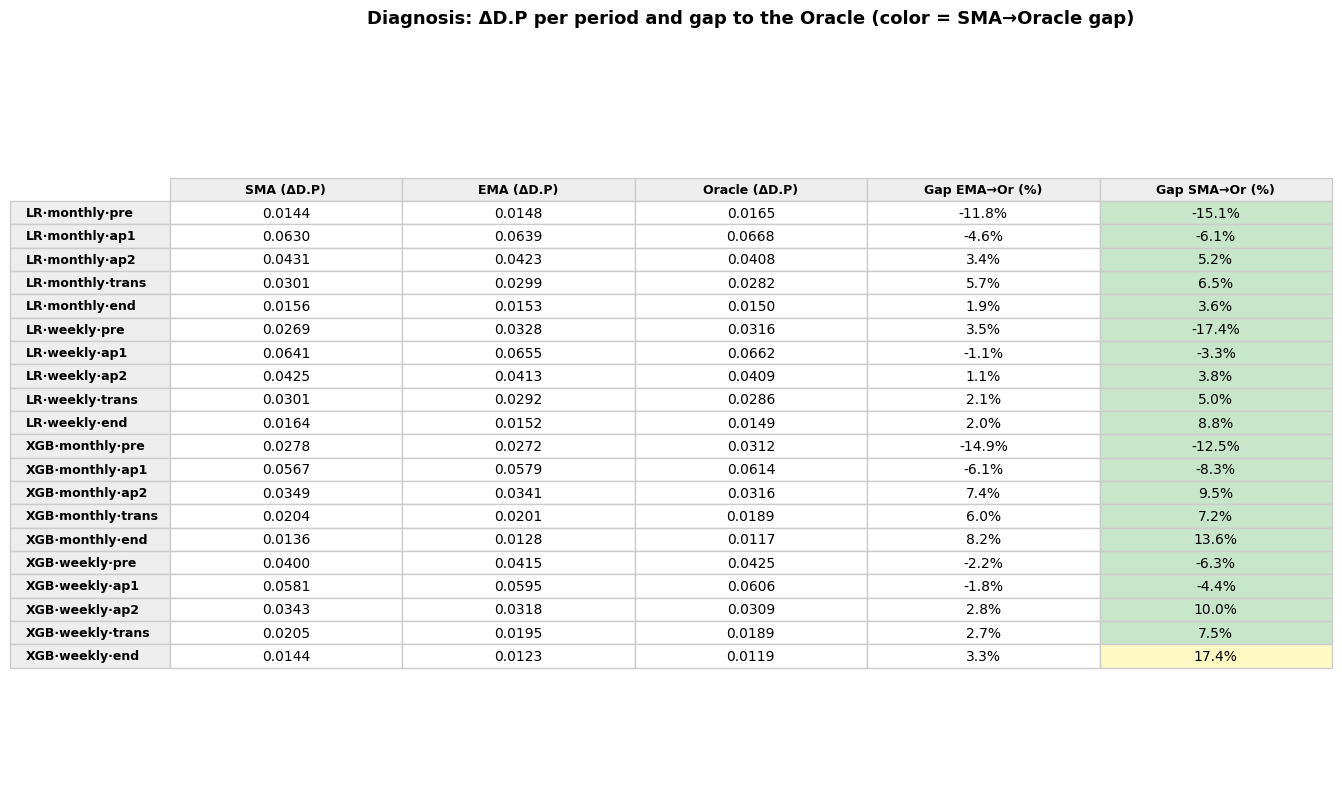

In [22]:
# Diagnosis table: ΔD.P per (model, batch_type, period) + gaps to the Oracle
_PERIOD_ABBR = {
    'pre-pandemic': 'pre', 'acute pandemic 1': 'ap1', 'acute pandemic 2': 'ap2',
    'transition': 'trans', 'endemic': 'end',
}


def _dp_period(model, bt, tech, period):
    s = abc3[(abc3['model_name'] == model) & (abc3['batch_type'] == bt)
            & (abc3['forecasting_technique'] == tech) & (abc3['period'] == period)]
    return s['dp'].mean()


rows_meta, cell_text, gap_sma_vals = [], [], []
for model in ['logistic_regression', 'xgboost']:
    for bt in ['monthly', 'weekly']:
        for period in PERIOD_ORDER_EN:
            dp_sma = _dp_period(model, bt, 'sma', period)
            dp_ema = _dp_period(model, bt, 'ema', period)
            dp_or = _dp_period(model, bt, 'oracle', period)
            gap_ema = (dp_ema - dp_or) / dp_ema * 100 if dp_ema else float('nan')
            gap_sma = (dp_sma - dp_or) / dp_sma * 100 if dp_sma else float('nan')
            rows_meta.append((_MODEL_ABBR[model], bt, _PERIOD_ABBR[period]))
            cell_text.append([f'{dp_sma:.4f}', f'{dp_ema:.4f}', f'{dp_or:.4f}',
                              f'{gap_ema:.1f}%', f'{gap_sma:.1f}%'])
            gap_sma_vals.append(gap_sma)

col_labels = ['SMA (ΔD.P)', 'EMA (ΔD.P)', 'Oracle (ΔD.P)', 'Gap EMA→Or (%)', 'Gap SMA→Or (%)']
row_labels = [f'{m}·{bt}·{p}' for (m, bt, p) in rows_meta]

fig, ax = plt.subplots(figsize=(15, 0.42 * len(rows_meta) + 1.4))
ax.axis('off')

tbl = ax.table(cellText=cell_text, rowLabels=row_labels, colLabels=col_labels,
               cellLoc='center', loc='center')
tbl.auto_set_font_size(False)
tbl.set_fontsize(10)
tbl.scale(1, 1.4)


def _gap_color(g):
    if pd.isna(g):
        return 'white'
    if g < 15:
        return '#c8e6c9'   # green: oracle does not improve much -> reweighing may be the bottleneck
    if g < 30:
        return '#fff9c4'   # amarelo: moderado, inconclusivo
    return '#ffcdd2'       # red: forecasting is the bottleneck (SCENARIO A)


gap_col = len(col_labels) - 1  # 'Gap SMA→Or (%)'
for (r, c), cell in tbl.get_celld().items():
    cell.set_edgecolor('#cccccc')
    if r == 0 or c == -1:
        cell.set_facecolor('#eeeeee')
        cell.get_text().set_fontweight('bold')
        cell.get_text().set_fontsize(9)
    elif c == gap_col:
        cell.set_facecolor(_gap_color(gap_sma_vals[r - 1]))

ax.set_title('Diagnosis: ΔD.P per period and gap to the Oracle (color = SMA→Oracle gap)',
             fontsize=13, fontweight='bold', pad=16)

out_path = fq_root / 'triple_comparison_table.png'
fig.savefig(out_path, dpi=150, bbox_inches='tight')
plt.show()

In [23]:
# Automatic decision criterion (global mean: all periods and batches)
IMPROVEMENT_THRESHOLD = 0.30

for model in ['logistic_regression', 'xgboost']:
    for batch_type in ['monthly', 'weekly']:
        sel = abc3[(abc3['model_name'] == model) & (abc3['batch_type'] == batch_type)]
        dp_sma = sel[sel['forecasting_technique'] == 'sma']['dp'].mean()
        dp_oracle = sel[sel['forecasting_technique'] == 'oracle']['dp'].mean()
        gap = (dp_sma - dp_oracle) / dp_sma

        if gap > IMPROVEMENT_THRESHOLD:
            print(f'[{model} | {batch_type}] SCENARIO A: forecasting is the bottleneck (gap={gap:.1%})')
        else:
            print(f'[{model} | {batch_type}] SCENARIO B: reweighing is the bottleneck (gap={gap:.1%})')

[logistic_regression | monthly] SCENARIO B: reweighing is the bottleneck (gap=-1.4%)
[logistic_regression | weekly] SCENARIO B: reweighing is the bottleneck (gap=-0.5%)
[xgboost | monthly] SCENARIO B: reweighing is the bottleneck (gap=-1.2%)
[xgboost | weekly] SCENARIO B: reweighing is the bottleneck (gap=1.7%)
